# Лабораторная работа 3. Кластеризация

**Выполнил:** Гладышев Р.М.  
**Проверил:** Антонянц Е.Н.  
**Датасет:** Countries Data Set — сводная таблица социально-экономических, демографических и географических показателей 196 стран.  
**Задача:** кластеризация (типологизация) стран по семи числовым признакам уровня развития и структуры землепользования: ВВП на душу населения (`GDPpc`, log10), ожидаемая продолжительность жизни (`LifeExp`), рождаемость (`Birthrate`), доля городского населения (`Urban`), выбросы CO₂ на душу населения (`CO2pc`, log10), доля лесов (`Forest`) и доля сельскохозяйственных земель (`AgriLand`). Меток классов нет; колонка `Region` в кластеризации не участвует и используется только как справочная категория.  
**План работы:** описательный анализ и проверка условий применимости кластеризации → стандартизация → матрица диаграмм рассеивания и обоснование методов → подбор числа кластеров (локоть, силуэт, дендрограмма) → K-means и иерархическая кластеризация (метод Уорда) → внутренние и внешние метрики качества → влияние параметров и устойчивость → визуализация (PCA) и интерпретация кластеров → сравнение методов → заключение.

## Введение

**Цель работы** — изучить алгоритмы кластеризации, приобрести навыки оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи:**

1. загрузить датасет и провести дескриптивный анализ: размерность, типы признаков, пропуски, распределения (гистограммы), информационная значимость признаков;
2. проверить условия применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов;
3. выполнить стандартизацию числовых признаков и обосновать выбор метода масштабирования;
4. построить матрицу диаграмм рассеивания, оценить число и форму кластеров, аргументированно выбрать два метода кластеризации;
5. подобрать число кластеров *k* методом локтя, анализом силуэта и по дендрограмме;
6. реализовать кластеризацию двумя методами (K-means и иерархическая кластеризация), рассчитать внутренние и внешние метрики качества, расстояния между кластерами, компактность, центры;
7. исследовать влияние параметров метода (числа кластеров *k*, инициализации, способа объединения кластеров) и устойчивость разбиения;
8. визуализировать кластеры (PCA), интерпретировать центры кластеров, сравнить результаты двух методов.

**О «внешних» метриках.** В данных нет истинных классов, поэтому внешние метрики (Rand, ARI, Жаккар, NMI, однородность, полнота, V-мера) в этой работе измеряют **согласованность двух разбиений между собой**: (а) K-means против метода Уорда и (б) каждого из методов против справочной группировки стран по регионам (`Region`). Регион — не «истинный класс» и не «правильный ответ»: это географическая рубрика, которая лишь частично совпадает с уровнем развития. Поэтому высокие значения метрик против региона не были бы признаком хорошей кластеризации, а низкие — признаком плохой; они показывают, насколько кластеры воспроизводят географию. Это корректная адаптация необязательной (по заданию) оценки с эталоном, и далее в работе она проговаривается явно.

In [1]:
%matplotlib inline
import warnings, random
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform, cdist

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure)
from sklearn.metrics.cluster import pair_confusion_matrix, contingency_matrix

SEED = 42                                   # единое зерно для воспроизводимости
random.seed(SEED); np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)
print("scikit-learn:", __import__("sklearn").__version__)


scikit-learn: 1.9.1


**Пояснение к блоку кода.** Подключаем библиотеки: `pandas`, `numpy`, `scipy` — данные, статистика, иерархическая кластеризация и расстояния; `matplotlib`, `seaborn` — графики; `scikit-learn` — стандартизация, PCA, алгоритмы кластеризации (`KMeans`, `AgglomerativeClustering`) и метрики качества. Константа `SEED = 42` и вызовы `random.seed`, `np.random.seed` фиксируют случайные числа, чтобы эксперименты воспроизводились; во всех случайных алгоритмах дополнительно задаётся `random_state`. Предупреждения отключены, настроен единый формат вывода чисел.

## 1. Загрузка данных и дескриптивный анализ

In [2]:
DATA_PATH = "Countries Data Set.csv"
raw = pd.read_csv(DATA_PATH)                       # в файле пропуски закодированы символом «?»
print("Размер исходной таблицы (строки, столбцы):", raw.shape)
print("Типы столбцов при прямом чтении (object/str = столбец «испорчен» символом «?»):")
print(raw.dtypes.value_counts().to_string())

# «?» → NaN, числовые столбцы → float, пробелы в названии региона убираем
data = raw.replace("?", np.nan)
num_cols = [c for c in data.columns if c not in ("Country", "Region")]
data[num_cols] = data[num_cols].apply(pd.to_numeric, errors="coerce")
data["Region"] = data["Region"].str.strip()

miss = data.isna().sum().to_frame("пропусков")
miss["доля, %"] = miss["пропусков"] / len(data) * 100
print("\nСтолбцы с пропусками (все 37 столбцов, по убыванию):")
display(miss[miss["пропусков"] > 0].sort_values("пропусков", ascending=False).T)
print("Полных дубликатов строк:", data.duplicated().sum(), "| повторяющихся названий стран:", data["Country"].duplicated().sum())
print("\nРаспределение стран по регионам:")
display(data["Region"].value_counts(dropna=False).to_frame("стран").assign(**{"доля, %": data["Region"].value_counts(dropna=False, normalize=True) * 100}))
data.head()


Размер исходной таблицы (строки, столбцы): (196, 37)
Типы столбцов при прямом чтении (object/str = столбец «испорчен» символом «?»):
str        32
float64     3
int64       2

Столбцы с пропусками (все 37 столбцов, по убыванию):


,Minimum Wage,Unemployment Rate,Pop Labor Force Participation,Armed Forces Size,CPI,CPI Change,Gasoline Price,Maternity Mortality Ratio,Service,Total Tax Rate,Industry,Literacy,Agriculture,Phones,Deathrate,Life Expectancy,Pop.Density,Region,Coastline,Net migration,Physicians per Thousand,Fertility Rate,OOP Health Expentiture,Agriculture Land,Carbon Dioxide Emissions,Forested Area,Birthrate,Infant Mortality,Urban Population,GDP,GDP.per.capita
пропусков,26.0000,20.0000,20.0000,19.0000,17.0000,17.0000,16.0000,15.0000,13.0000,13.0000,13.0000,12.0000,11.0000,10.0000,9.0000,9.0000,9.0000,9.0000,9.0000,9.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,7.0000,7.0000,6.0000,1.0000,1.0000
"доля, %",13.2653,10.2041,10.2041,9.6939,8.6735,8.6735,8.1633,7.6531,6.6327,6.6327,6.6327,6.1224,5.6122,5.1020,4.5918,4.5918,4.5918,4.5918,4.5918,4.5918,4.0816,4.0816,4.0816,4.0816,4.0816,4.0816,3.5714,3.5714,3.0612,0.5102,0.5102


Полных дубликатов строк: 0 | повторяющихся названий стран: 0

Распределение стран по регионам:


,стран,"доля, %"
Region,,
SUB-SAHARAN AFRICA,46,23.4694
LATIN AMER. & CARIB,33,16.8367
ASIA (EX. NEAR EAST),25,12.7551
WESTERN EUROPE,23,11.7347
NEAR EAST,14,7.1429
OCEANIA,13,6.6327
C.W. OF IND. STATES,12,6.1224
EASTERN EUROPE,11,5.6122
NaN,9,4.5918


,Country,Region,Latitude,Longitude,Distance from Equator,GDP,Population,Urban Population,Pop.Density,GDP.per.capita,Birthrate,Infant Mortality,Fertility Rate,Maternity Mortality Ratio,Deathrate,Life Expectancy,Physicians per Thousand,OOP Health Expentiture,CPI,CPI Change,Gasoline Price,Minimum Wage,Total Tax Rate,Unemployment Rate,Pop Labor Force Participation,Literacy,Phones,Area,Coastline,Agriculture Land,Forested Area,Carbon Dioxide Emissions,Armed Forces Size,Agriculture,Industry,Service,Net migration
0,Austria,WESTERN EUROPE,47.5162,14.5501,47.5162,"446,000,000,000.0000",8877067,"5,194,416.0000",97.7000,"50,277.0000",9.7000,2.9000,1.4700,5.0000,9.7600,81.6000,5.1700,0.1800,118.0600,0.0200,1.2000,NaN,0.5100,0.0500,0.6100,98.0000,452.2000,83871,0.0000,0.3200,0.4700,"61,448.0000","21,000.0000",0.0200,0.3000,0.6800,2.0000
1,Denmark,WESTERN EUROPE,56.2639,9.5018,56.2639,"348,000,000,000.0000",5818553,"5,119,978.0000",126.5000,"59,822.0000",10.6000,3.6000,1.7300,4.0000,10.3600,81.0000,4.0100,0.1400,110.3500,0.0100,1.5500,NaN,0.2400,0.0500,0.6200,100.0000,614.6000,43094,16.9700,0.6200,0.1500,"31,786.0000","15,000.0000",0.0200,0.2500,0.7400,2.4800
2,Eritrea,SUB-SAHARAN AFRICA,15.1794,39.7823,15.1794,"2,065,001,626.0000",6333135,"1,149,670.0000",39.5000,326.0000,30.3000,31.3000,4.0600,480.0000,9.6000,65.9000,0.0600,0.5200,NaN,NaN,2.0000,NaN,0.8400,0.0500,0.7800,58.6000,7.9000,117600,1.8400,0.7500,0.1500,711.0000,"202,000.0000",0.1000,0.2500,0.6400,0.0000
3,Eswatini,SUB-SAHARAN AFRICA,-26.5225,31.4659,26.5225,"3,791,304,348.0000",1093238,NaN,65.5000,"3,468.0000",NaN,NaN,NaN,NaN,29.7400,NaN,NaN,0.1100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,81.6000,30.8000,17364,0.0000,NaN,NaN,NaN,NaN,0.1200,0.5200,0.3700,0.0000
4,Federated States of Micronesia,NaN,7.4256,150.5508,7.4256,"401,932,279.0000",113815,"25,963.0000",NaN,"3,531.0000",22.8200,25.6000,3.0500,88.0000,NaN,67.8000,0.1800,0.0300,112.1000,0.0100,NaN,NaN,0.6100,NaN,NaN,NaN,NaN,702,NaN,0.3100,0.9200,143.0000,NaN,NaN,NaN,NaN,NaN


**Пояснение к блоку кода.** Читаем таблицу «как есть» и показываем типы столбцов: 32 из 37 столбцов прочитались как строки, потому что пропуски в файле закодированы символом `?`. Заменяем `?` на `NaN`, приводим числовые столбцы к `float`, убираем лишние пробелы в названиях регионов (в файле они дополнены пробелами до фиксированной ширины). Затем считаем число и долю пропусков по всем столбцам, дубликаты и распределение стран по регионам.

**Вывод.** В таблице **196 стран и 37 столбцов**: идентификатор (`Country`), справочная категория (`Region`) и 35 числовых показателей. Дубликатов строк и повторяющихся названий стран нет. Пропусков много: они есть в 31 из 37 столбцов; больше всего у `Minimum Wage` (26, 13.3%), `Unemployment Rate` и `Pop Labor Force Participation` (по 20), `Armed Forces Size` (19), `CPI` и `CPI Change` (по 17). У самого признака `Region` неизвестно значение у 9 стран. Регионы распределены неравномерно: от 46 стран (Африка к югу от Сахары, 23.5%) до 2 стран (Северная Америка), поэтому как справочная рубрика регион информативен, но мелкие регионы (Балтия — 3, Северная Америка — 2) статистически слабы.

## Описание датасета

**Countries Data Set** — таблица из **196 стран** (по одной строке на страну) с 35 числовыми показателями: экономика (ВВП, ВВП на душу, ИПЦ, минимальная зарплата, налоговая нагрузка, безработица), демография и здоровье (население, рождаемость, детская и материнская смертность, продолжительность жизни, врачи на 1000 жителей), структура экономики (доли сельского хозяйства, промышленности и услуг), география и природа (широта, долгота, площадь, береговая линия, доли лесов и сельхозземель), энергетика и безопасность (выбросы CO₂, армия) и др.

| Признак в работе | Исходный столбец и преобразование | Единицы | Роль |
|---|---|---|---|
| `Country` | название страны | строка | идентификатор |
| `Region` | регион (в файле с хвостовыми пробелами; у части стран `?`) | категория | интерпретация и справочное разбиение |
| `GDPpc` | log₁₀(`GDP.per.capita`) | log₁₀ долл. на человека | признак кластеризации |
| `LifeExp` | `Life Expectancy` | лет | признак кластеризации |
| `Birthrate` | `Birthrate` | на 1000 жителей | признак кластеризации |
| `Urban` | `Urban Population` / `Population` × 100 | % населения | признак кластеризации |
| `CO2pc` | log₁₀(`Carbon Dioxide Emissions` × 1000 / `Population`) | log₁₀ т CO₂ на человека | признак кластеризации |
| `Forest` | `Forested Area` × 100 | % территории | признак кластеризации |
| `AgriLand` | `Agriculture Land` × 100 | % территории | признак кластеризации |

**Почему именно эти признаки.** Из 35 числовых столбцов нельзя брать все: у многих слишком много пропусков (`Minimum Wage`, `Unemployment Rate`, `Pop Labor Force Participation`, `CPI` — 8–13%), часть — абсолютные величины, которые отражают размер страны, а не её тип (`GDP`, `Population`, `Area`, `Armed Forces Size`), часть дублирует друг друга (`Infant Mortality`, `Fertility Rate` и `Maternity Mortality Ratio` по смыслу близки к рождаемости и продолжительности жизни). Выбраны семь относительных показателей с малой долей пропусков (0.5–4.6%), которые описывают уровень развития (`GDPpc`, `LifeExp`, `Birthrate`, `CO2pc`), урбанизацию (`Urban`) и землепользование (`Forest`, `AgriLand`). Датасет не содержит целевой переменной: это задача типологизации стран (обучение без учителя).

In [3]:
# Конструирование признаков: асимметричные величины логарифмируем, абсолютные — переводим в относительные
feat = pd.DataFrame({"Country": data["Country"], "Region": data["Region"]})
feat["GDPpc"]    = np.log10(data["GDP.per.capita"])                                   # log10 ВВП на душу, $
feat["LifeExp"]  = data["Life Expectancy"]                                            # лет
feat["Birthrate"] = data["Birthrate"]                                                 # рождаемость, на 1000 жителей
feat["Urban"]    = data["Urban Population"] / data["Population"] * 100                # доля городского населения, %
feat["CO2pc"]    = np.log10(data["Carbon Dioxide Emissions"] * 1000 / data["Population"])   # log10 выбросов CO2, т на человека
feat["Forest"]   = data["Forested Area"] * 100                                        # доля лесов, %
feat["AgriLand"] = data["Agriculture Land"] * 100                                     # доля сельхозземель, %
FEATURES = ["GDPpc", "LifeExp", "Birthrate", "Urban", "CO2pc", "Forest", "AgriLand"]

# исходные (нелогарифмированные) значения — для содержательной интерпретации кластеров
orig = pd.DataFrame({"ВВП на душу, $": data["GDP.per.capita"], "Продолжительность жизни, лет": data["Life Expectancy"],
                     "Рождаемость, ‰": data["Birthrate"], "Городское население, %": feat["Urban"],
                     "CO2 на душу, т": data["Carbon Dioxide Emissions"] * 1000 / data["Population"],
                     "Леса, %": feat["Forest"], "Сельхозземли, %": feat["AgriLand"]})

print("Пропуски по выбранным признакам:", feat[FEATURES].isna().sum().to_dict())
mask = feat[FEATURES].notna().all(axis=1)
print(f"Стран с полным набором признаков: {mask.sum()} из {len(feat)} (исключено {(~mask).sum()}):")
print(", ".join(feat.loc[~mask, "Country"]))
df = feat[mask].reset_index(drop=True)                 # рабочая таблица
orig = orig[mask].reset_index(drop=True)
print("\nРабочая таблица:", df.shape, "| стран с неизвестным регионом:", df["Region"].isna().sum())
df.head()


Пропуски по выбранным признакам: {'GDPpc': 1, 'LifeExp': 9, 'Birthrate': 7, 'Urban': 6, 'CO2pc': 8, 'Forest': 8, 'AgriLand': 8}
Стран с полным набором признаков: 185 из 196 (исключено 11):
Eswatini, Nauru, Republic of North Macedonia, San Marino, South Sudan, Tuvalu, Vatican City, Monaco, Andorra, Taiwan, Kosovo

Рабочая таблица: (185, 9) | стран с неизвестным регионом: 5


,Country,Region,GDPpc,LifeExp,Birthrate,Urban,CO2pc,Forest,AgriLand
0,Austria,WESTERN EUROPE,4.7014,81.6000,9.7000,58.5150,0.8402,47.0000,32.0000
1,Denmark,WESTERN EUROPE,4.7769,81.0000,10.6000,87.9940,0.7374,15.0000,62.0000
2,Eritrea,SUB-SAHARAN AFRICA,2.5132,65.9000,30.3000,18.1533,-0.9497,15.0000,75.0000
3,Federated States of Micronesia,NaN,3.5479,67.8000,22.8200,22.8116,0.0991,92.0000,31.0000
4,Finland,WESTERN EUROPE,4.6874,81.7000,8.6000,85.4460,0.9196,73.0000,8.0000


**Пояснение к блоку кода.** Строим рабочие признаки. Асимметричные положительные величины (ВВП на душу и выбросы CO₂ на душу) логарифмируем по основанию 10: их значения охватывают несколько порядков (от сотен до сотен тысяч долларов), и без логарифма несколько богатых или «грязных» стран определяли бы масштаб признака. Абсолютные показатели переводим в относительные (доля городского населения, выбросы на душу). В таблице `orig` сохраняем те же признаки в исходных единицах — они нужны для содержательной интерпретации кластеров (например, ВВП в долларах, а не в log₁₀). Затем оставляем только страны с полным набором из семи признаков.

**Вывод.** Полный набор признаков есть у **185 стран из 196**; исключены 11 стран (Eswatini, Nauru, Республика Северная Македония, San Marino, Южный Судан, Tuvalu, Vatican City, Monaco, Andorra, Taiwan, Kosovo) — в основном микрогосударства и страны, по которым недоступна статистика. Удаление строк с пропусками выбрано вместо заполнения медианами: стран достаточно, а заполнение «типичным» значением искусственно делало бы страну похожей на центр выборки и сглаживало бы структуру. Потеря 5.6% выборки меняет её состав умеренно; следует помнить, что среди исключённых много очень малых государств, поэтому выводы относятся к «обычным» суверенным странам. В рабочей таблице у 5 стран неизвестен регион: они участвуют в кластеризации, но исключаются из сравнения с регионами.

In [4]:
desc = df[FEATURES].describe().T
desc["skew"] = df[FEATURES].skew()
desc["CV, %"] = desc["std"] / desc["mean"].abs() * 100      # коэффициент вариации
display(desc)

# что дало бы логарифмирование: асимметрия до и после
chk = pd.DataFrame({"до логарифма": [orig["ВВП на душу, $"].skew(), orig["CO2 на душу, т"].skew()],
                    "после log10": [df["GDPpc"].skew(), df["CO2pc"].skew()]}, index=["ВВП на душу", "CO2 на душу"])
display(chk)


,count,mean,std,min,25%,50%,75%,max,skew,"CV, %"
GDPpc,185.0000,3.7609,0.6336,2.4166,3.2813,3.7749,4.2374,5.2364,-0.0159,16.8478
LifeExp,185.0000,72.2881,7.3829,52.8000,67.1000,73.2000,77.4000,84.2000,-0.5471,10.2132
Birthrate,185.0000,20.3552,9.8411,6.4000,11.5000,18.0700,28.7500,46.0800,0.5921,48.3467
Urban,185.0000,58.3680,22.9886,11.4338,40.7660,58.7600,77.4166,100.0000,-0.2055,39.3857
CO2pc,185.0000,0.2733,0.6503,-1.6329,-0.1960,0.3890,0.7586,1.5618,-0.6134,237.9515
Forest,185.0000,32.2270,23.8433,0.0000,11.0000,32.0000,48.0000,98.0000,0.5147,73.9854
AgriLand,185.0000,39.1676,21.8463,1.0000,22.0000,40.0000,55.0000,83.0000,0.0946,55.7764


,до логарифма,после log10
ВВП на душу,3.2114,-0.0159
CO2 на душу,2.7924,-0.6134


**Пояснение к блоку кода.** Для семи признаков вычислена описательная статистика (`describe`) с коэффициентом асимметрии (`skew`) и коэффициентом вариации (`CV = σ/|μ|`). Дополнительно показано, как логарифмирование изменило асимметрию двух признаков.

**Вывод.** Признаки охватывают широкий диапазон: продолжительность жизни 52.8–84.2 года (среднее 72.3, σ ≈ 7.4), рождаемость 6.4–46.1‰ (среднее 20.4, σ ≈ 9.8), доля городского населения 11–100% (среднее 58.4, σ ≈ 23.0), доля лесов 0–98% (среднее 32.2, σ ≈ 23.8), доля сельхозземель 1–83% (среднее 39.2, σ ≈ 21.8). Логарифмирование выровняло распределения: асимметрия ВВП на душу снизилась с 3.21 до −0.02, выбросов CO₂ на душу — с 2.79 до −0.61. Для логарифмических признаков коэффициент вариации неинформативен (у `CO2pc` он 238%, потому что среднее log₁₀ близко к нулю), поэтому разброс лучше оценивать по σ: 0.63 для `GDPpc` (т.е. около порядка величины по ВВП на душу) и 0.65 для `CO2pc`. Единицы измерения у признаков разные (годы, ‰, проценты, log₁₀), так что масштаб нужно выравнивать.

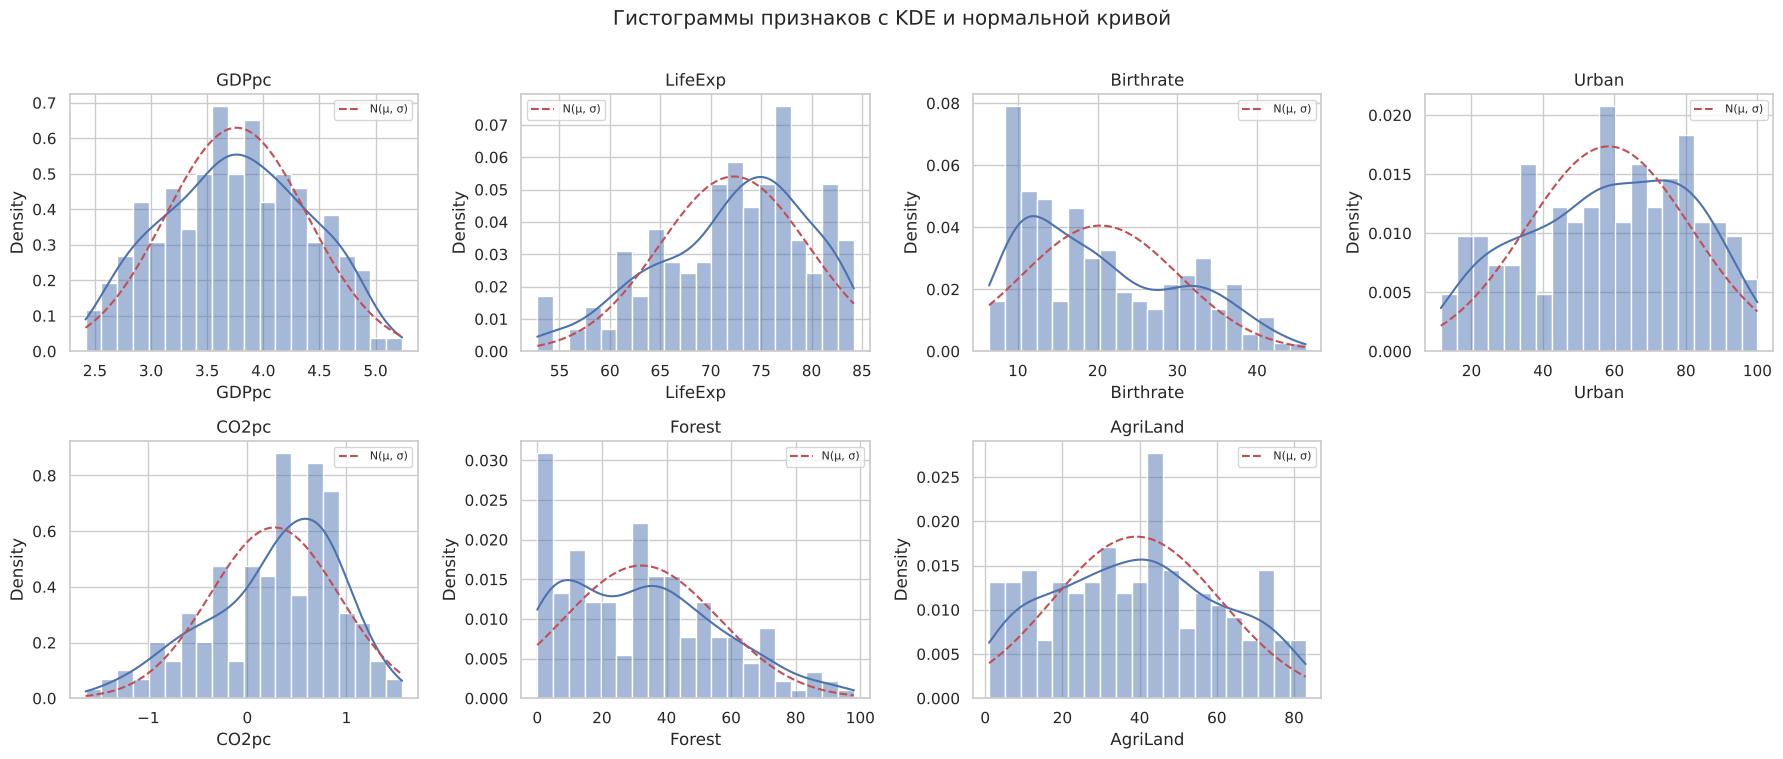

,асимметрия,эксцесс,W (Шапиро–Уилк),p-value
признак,,,,
GDPpc,-0.0158,-0.7997,0.9843,0.0365
LifeExp,-0.5427,-0.3823,0.9606,0.0000
Birthrate,0.5873,-0.8106,0.9221,0.0000
Urban,-0.2038,-0.9586,0.9692,0.0004
CO2pc,-0.6084,-0.1891,0.9646,0.0001
Forest,0.5105,-0.4951,0.9500,0.0000
AgriLand,0.0938,-0.9561,0.9702,0.0005


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df[col], bins=20, kde=True, stat="density", color="#4C72B0", ax=ax)
    mu, sd = df[col].mean(), df[col].std()
    xs = np.linspace(df[col].min(), df[col].max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), color="#C44E52", ls="--", label="N(μ, σ)")
    ax.set_title(col); ax.legend(fontsize=8)
axes.ravel()[-1].axis("off")
plt.suptitle("Гистограммы признаков с KDE и нормальной кривой", y=1.01)
plt.tight_layout(); plt.show()

norm_rows = []
for col in FEATURES:
    w, p = stats.shapiro(df[col])
    norm_rows.append({"признак": col, "асимметрия": stats.skew(df[col]), "эксцесс": stats.kurtosis(df[col]),
                      "W (Шапиро–Уилк)": w, "p-value": p})
pd.DataFrame(norm_rows).set_index("признак")


**Пояснение к блоку кода.** Для каждого признака строим гистограмму с оценкой плотности (KDE) и накладываем плотность нормального распределения с теми же средним и стандартным отклонением; в таблице приводим асимметрию, эксцесс и критерий Шапиро–Уилка (нулевая гипотеза — нормальность). Цель — оценить близость распределений к нормальному.

**Вывод.** Строго нормальным не является ни один признак: Шапиро–Уилк отвергает нормальность на уровне 5% для всех семи (для `GDPpc` p = 0.037 — граничный случай, для остальных p < 0.001). При этом отклонения умеренные: асимметрия лежит в пределах от −0.61 (`CO2pc`) до 0.59 (`Birthrate`), эксцесс отрицательный (−0.2…−1.0), т.е. распределения «плосковатые» (часть — двугорбые). Особенно заметно: у `Birthrate` два максимума плотности (около 12‰ и 32‰), у `Forest` — тоже два (около 10% и 38%): это признаки возможной групповой структуры. `LifeExp` и `CO2pc` имеют левый хвост (низкие значения у наименее развитых стран). Сильных перекосов нет, дополнительные преобразования не требуются. Для K-means и метода Уорда строгая нормальность не обязательна.

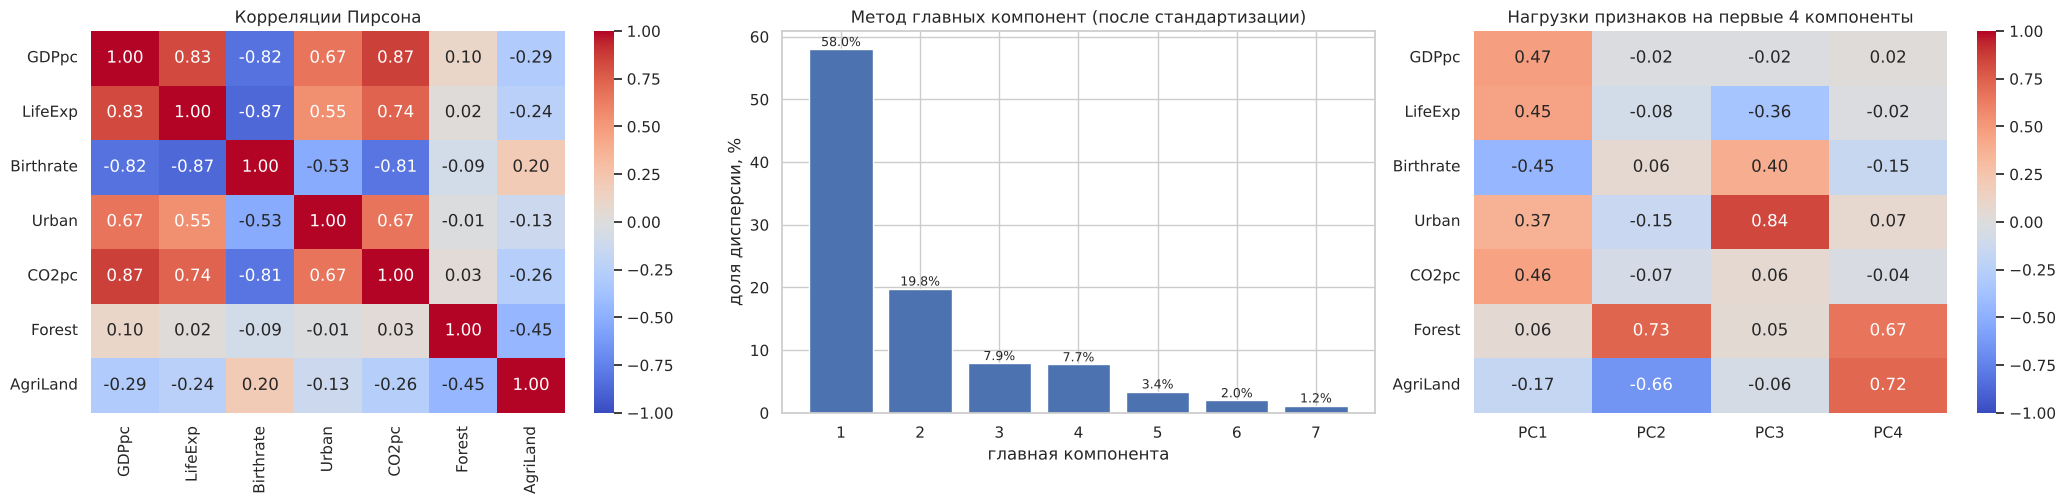

Накопленная доля дисперсии, %: [58.0, 77.8, 85.7, 93.5, 96.9, 98.8, 100.0]


,H (Краскел–Уоллис),p-value,"ε² (доля вариации, объяснённая регионом)"
признак,,,
GDPpc,107.5454,0.0000,0.5772
LifeExp,125.6064,0.0000,0.6841
Birthrate,121.9775,0.0000,0.6626
Urban,57.2999,0.0000,0.2799
CO2pc,85.7918,0.0000,0.4485
Forest,52.2396,0.0000,0.2499
AgriLand,25.2149,0.0050,0.0900


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.2))
corr = df[FEATURES].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Корреляции Пирсона")

Xtmp = StandardScaler().fit_transform(df[FEATURES])
pca_full = PCA().fit(Xtmp)
ev = pca_full.explained_variance_ratio_ * 100
axes[1].bar(range(1, len(ev) + 1), ev, color="#4C72B0")
for i, v in enumerate(ev):
    axes[1].text(i + 1, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
axes[1].set_xticks(range(1, len(ev) + 1)); axes[1].set_xlabel("главная компонента"); axes[1].set_ylabel("доля дисперсии, %")
axes[1].set_title("Метод главных компонент (после стандартизации)")

loadings = pd.DataFrame(pca_full.components_[:4].T, index=FEATURES, columns=["PC1", "PC2", "PC3", "PC4"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[2])
axes[2].set_title("Нагрузки признаков на первые 4 компоненты")
plt.tight_layout(); plt.show()
print("Накопленная доля дисперсии, %:", np.cumsum(ev).round(1).tolist())

# связь признаков с регионом (регион — справочная категория, а не метка класса): критерий Краскела–Уоллиса
kw_rows = []
known = df[df["Region"].notna()]
for col in FEATURES:
    groups = [g[col].values for _, g in known.groupby("Region") if len(g) > 1]
    H, p = stats.kruskal(*groups)
    eps2 = (H - len(groups) + 1) / (len(known) - len(groups))            # ε² — размер эффекта
    kw_rows.append({"признак": col, "H (Краскел–Уоллис)": H, "p-value": p, "ε² (доля вариации, объяснённая регионом)": eps2})
display(pd.DataFrame(kw_rows).set_index("признак"))


**Пояснение к блоку кода.** Информационную значимость признаков оцениваем тремя способами: (1) корреляционная матрица — не дублируют ли признаки друг друга; (2) метод главных компонент (PCA) после стандартизации — сколько независимой информации несёт каждое направление и как признаки в него входят; (3) связь признаков со справочной группировкой по регионам (критерий Краскела–Уоллиса и размер эффекта ε² — доля вариации признака, объяснённая регионом). Регион здесь — не метка класса, а справочная категория.

**Вывод.** Признаки **сильно избыточны внутри блока «развитие»**: `GDPpc`, `LifeExp`, `Birthrate` и `CO2pc` связаны с |r| = 0.74–0.87 (например, `GDPpc`–`CO2pc` 0.87, `LifeExp`–`Birthrate` −0.87, `GDPpc`–`LifeExp` 0.83, `GDPpc`–`Birthrate` −0.82). `Urban` с ними связан умереннее (|r| = 0.53–0.67), а `Forest` и `AgriLand` почти не зависят от развития (|r| ≤ 0.29) и связаны между собой отрицательно (−0.45). PCA подтверждает это: первая компонента объясняет **58.0%** дисперсии, вторая — 19.8%, третья — 7.9% (первые две — 77.8%, первые четыре — 93.5%). PC1 — «ось развития» (нагрузки `GDPpc` 0.47, `CO2pc` 0.46, `LifeExp` 0.45, `Birthrate` −0.45, `Urban` 0.37), PC2 — «лес против сельхозземель» (`Forest` 0.73, `AgriLand` −0.66), PC3 — в основном урбанизация (`Urban` 0.84). Это важное отличие от «независимых» признаков: четыре из семи признаков несут один и тот же фактор, и в евклидовом расстоянии он получает примерно вчетверо больший вес, чем землепользование. Мы принимаем это сознательно (кластеризация стран по уровню развития — содержательная задача), но в выводах учитываем, что **кластеры в первую очередь отражают уровень развития**, а структура землепользования влияет на них слабее. Связь с регионом сильная для признаков развития (ε² = 0.68 у `LifeExp`, 0.66 у `Birthrate`, 0.58 у `GDPpc`, 0.45 у `CO2pc`), умеренная у `Urban` и `Forest` (0.28 и 0.25) и слабая у `AgriLand` (0.09); для всех признаков p < 0.01. Все семь признаков информативны и оставлены в анализе.

## 2. Проверка условий применимости кластеризации

,нижняя граница,верхняя граница,выбросов по IQR,выбросов по |z|>3,max |z|
признак,,,,,
GDPpc,1.8470,5.6717,0,0,2.3350
LifeExp,51.6500,92.8500,0,0,2.6468
Birthrate,-14.3750,54.6250,0,0,2.6211
Urban,-14.2099,132.3925,0,0,2.0472
CO2pc,-1.6278,2.1903,1,0,2.9393
Forest,-44.5000,103.5000,0,0,2.7660
AgriLand,-27.5000,104.5000,0,0,2.0118


Страны с наибольшим |z| по какому-либо признаку:


,Country,Region,GDPpc,LifeExp,Birthrate,Urban,CO2pc,Forest,AgriLand
167,Democratic Republic of the Congo,SUB-SAHARAN AFRICA,-1.6200,-1.6100,2.1200,-0.5800,-2.9400,1.4600,-1.2500
101,Suriname,LATIN AMER. & CARIB,0.1200,-0.0900,-0.1800,0.3400,0.3100,2.7700,-1.7500
145,Central African Republic,SUB-SAHARAN AFRICA,-1.7300,-2.6500,1.5300,-0.7200,-2.2800,0.1600,-1.4300
157,Niger,SUB-SAHARAN AFRICA,-1.6100,-1.4000,2.6200,-1.8300,-2.0600,-1.3100,-0.1500
14,Somalia,SUB-SAHARAN AFRICA,-2.0200,-2.0600,2.1800,-0.5600,-2.5500,-0.9300,1.4200
181,Burundi,SUB-SAHARAN AFRICA,-2.1300,-1.5100,1.9000,-1.9600,-2.5300,-0.8900,1.8300
137,Lesotho,SUB-SAHARAN AFRICA,-1.1000,-2.5200,0.6600,-1.3000,-0.3100,-1.2700,1.7800
3,Federated States of Micronesia,NaN,-0.3400,-0.6100,0.2500,-1.5500,-0.2700,2.5100,-0.3700


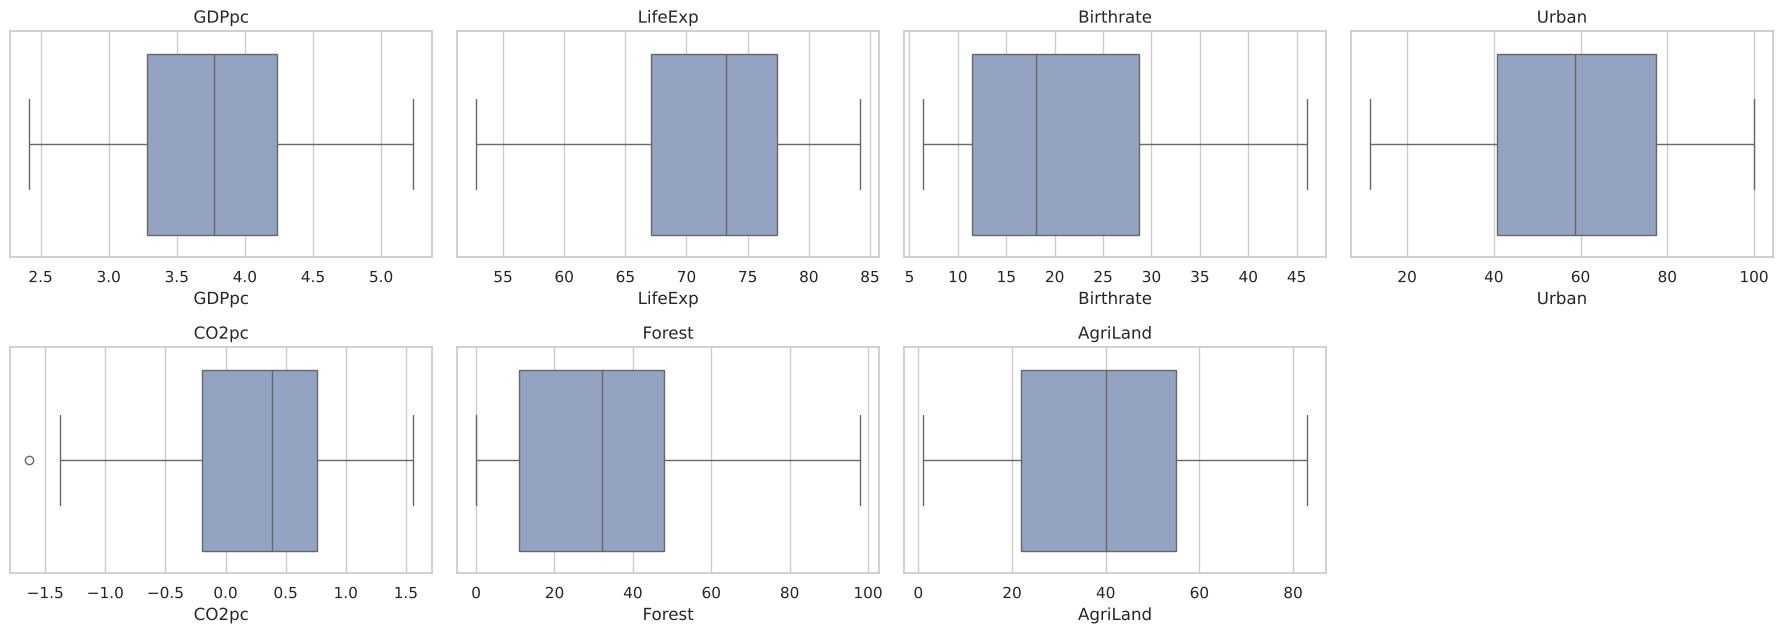

Статистика Хопкинса для данных: 0.705 ± 0.020  (контроль — равномерный шум: 0.488)


In [7]:
# 1) выбросы: правило 1.5·IQR и |z| > 3
out_rows = []
for col in FEATURES:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = stats.zscore(df[col])
    out_rows.append({"признак": col, "нижняя граница": lo, "верхняя граница": hi,
                     "выбросов по IQR": int(((df[col] < lo) | (df[col] > hi)).sum()),
                     "выбросов по |z|>3": int((np.abs(z) > 3).sum()), "max |z|": np.abs(z).max()})
display(pd.DataFrame(out_rows).set_index("признак"))

Zall = pd.DataFrame(stats.zscore(df[FEATURES]), columns=FEATURES)
extreme = Zall.abs().max(axis=1).sort_values(ascending=False).head(8).index
print("Страны с наибольшим |z| по какому-либо признаку:")
display(pd.concat([df.loc[extreme, ["Country", "Region"]], Zall.loc[extreme].round(2)], axis=1))

fig, axes = plt.subplots(2, 4, figsize=(18, 6.5))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(x=df[col], color="#8DA0CB", ax=ax); ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

# 2) склонность к кластеризации: статистика Хопкинса (≈0.5 — равномерные данные, → 1 — выраженные кластеры)
def hopkins(X, m=None, n_rep=200, seed=SEED):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    m = m or max(5, int(0.1 * n))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    lo, hi = X.min(0), X.max(0)
    vals = []
    for _ in range(n_rep):
        U = rng.uniform(lo, hi, size=(m, d))
        u = nn.kneighbors(U, n_neighbors=1)[0].ravel()                       # от случайных точек до ближайшей точки данных
        idx = rng.choice(n, m, replace=False)
        w = nn.kneighbors(X[idx], n_neighbors=2)[0][:, 1]                    # от точек данных до ближайшей другой точки данных
        vals.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(vals)), float(np.std(vals))

Xs_tmp = StandardScaler().fit_transform(df[FEATURES])
H, H_sd = hopkins(Xs_tmp)
rng = np.random.default_rng(SEED)
H_unif = hopkins(rng.uniform(Xs_tmp.min(0), Xs_tmp.max(0), size=Xs_tmp.shape))[0]       # контроль: равномерные данные
print(f"Статистика Хопкинса для данных: {H:.3f} ± {H_sd:.3f}  (контроль — равномерный шум: {H_unif:.3f})")


**Пояснение к блоку кода.** Проверяем условия применения кластеризации. **Отсутствие классов:** в таблице нет целевой переменной (регион классом не является). **Выбросы:** правило 1.5·IQR (граница по межквартильному размаху) и правило трёх сигм (|z| > 3), диаграммы «ящик с усами», список стран с наибольшим |z|. **Осмысленность кластеризации:** статистика Хопкинса *H* — доля, в которой расстояния от случайных точек до данных больше расстояний между самими данными. Для равномерно распределённых данных *H* ≈ 0.5, для данных с кластерной структурой *H* → 1. Для контроля статистика рассчитана и на искусственном равномерном «шуме» того же размера.

**Вывод.** Классов нет, задача — обучение без учителя. Выбросов по правилу трёх сигм нет (максимальный |z| = 2.94 у `CO2pc`, страна — Демократическая Республика Конго). По IQR отмечена одна страна — по самому низкому значению `CO2pc` (граница −1.63, у ДР Конго −1.633, т.е. практически на границе). Значения правдоподобны (это одна из беднейших стран), поэтому она оставлена — удаление уменьшило бы информацию о «хвосте» наименее развитых стран. Среди наиболее экстремальных наблюдений в основном страны Африки к югу от Сахары (ДР Конго, ЦАР, Нигер, Сомали, Бурунди, Лесото) — это край «оси развития», а не ошибки данных; ещё Суринам (доля лесов 98%). Статистика Хопкинса: **0.705 ± 0.020** против 0.488 на равномерных данных — данные заметно неоднородны, структура есть, но выражена умеренно (не 0.9+). Кластеризация осмысленна, но стоит ожидать не изолированных групп, а плавного перехода между ними (проверим на диаграммах).

## 3. Стандартизация признаков

до                            после                      
             mean     std     min      max    mean    std     min    max
GDPpc      3.7609  0.6336  2.4166   5.2364 -0.0000 1.0027 -2.1273 2.3350
LifeExp   72.2881  7.3829 52.8000  84.2000 -0.0000 1.0027 -2.6468 1.6178
Birthrate 20.3552  9.8411  6.4000  46.0800  0.0000 1.0027 -1.4219 2.6211
Urban     58.3680 22.9886 11.4338 100.0000 -0.0000 1.0027 -2.0472 1.8159
CO2pc      0.2733  0.6503 -1.6329   1.5618  0.0000 1.0027 -2.9393 1.9869
Forest    32.2270 23.8433  0.0000  98.0000 -0.0000 1.0027 -1.3553 2.7660
AgriLand  39.1676 21.8463  1.0000  83.0000  0.0000 1.0027 -1.7518 2.0118

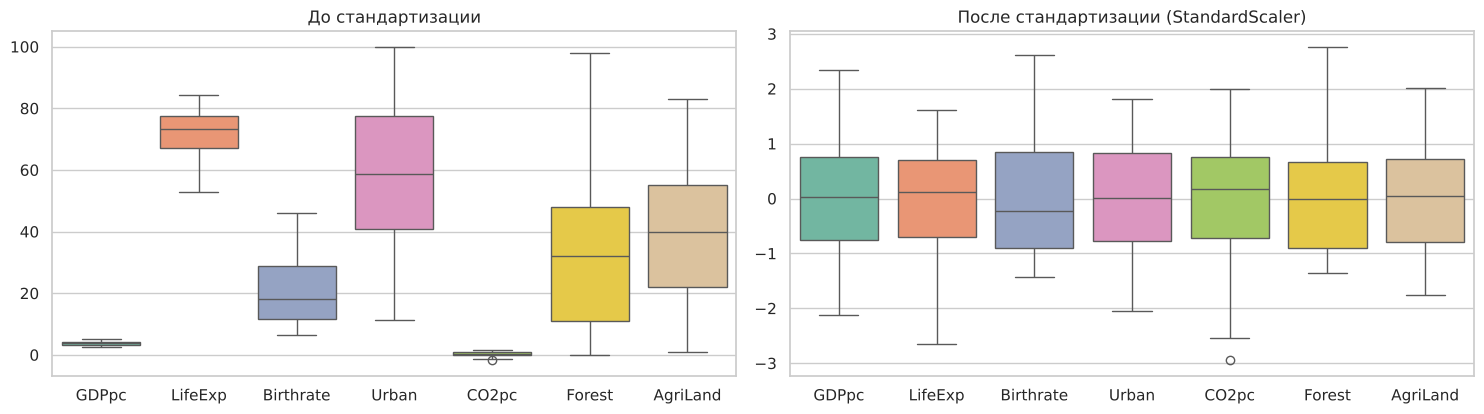

In [8]:
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])           # стандартизация: z = (x − μ) / σ
Xdf = pd.DataFrame(X, columns=FEATURES)

before = df[FEATURES].agg(["mean", "std", "min", "max"]).T
after = Xdf.agg(["mean", "std", "min", "max"]).T
display(pd.concat({"до": before, "после": after}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
sns.boxplot(data=df[FEATURES], ax=axes[0], palette="Set2"); axes[0].set_title("До стандартизации")
sns.boxplot(data=Xdf, ax=axes[1], palette="Set2"); axes[1].set_title("После стандартизации (StandardScaler)")
plt.tight_layout(); plt.show()


**Пояснение к блоку кода.** Применяем `StandardScaler`: каждый признак преобразуется как z = (x − μ)/σ, после чего среднее равно 0, а стандартное отклонение — 1. Таблица сравнивает статистику до и после, диаграммы «ящик с усами» показывают масштабы признаков.

**Вывод.** До стандартизации признаки имеют несопоставимые масштабы (доли в процентах 0–100, продолжительность жизни 53–84, log₁₀ ВВП 2.4–5.2), и признаки с большим размахом (`Urban`, `Forest`, `AgriLand`) доминировали бы в евклидовом расстоянии, а логарифмические — почти не влияли бы. После преобразования все признаки центрированы (среднее ≈ 0) и имеют единичный разброс (σ = 1.0027 — это поправка `ddof=0` в `StandardScaler` против `ddof=1` в `pandas`), диапазон примерно −2.9…2.8. **Обоснование выбора:** (1) K-means и метод Уорда основаны на евклидовом расстоянии и минимизации суммы квадратов, поэтому чувствительны к масштабу (так же рекомендует задание); (2) после логарифмирования признаки близки к симметричным и выбросов нет, поэтому стандартизация не искажает форму распределений; (3) при min–max нормализации масштаб задавался бы только крайними значениями (например, наибольшим ВВП на душу или нулевой долей лесов у ряда стран), а в `StandardScaler` масштаб определяется разбросом всей выборки. Далее все алгоритмы работают с матрицей `X` — стандартизованными признаками.

## 4. Структура данных: диаграммы рассеивания и выбор методов

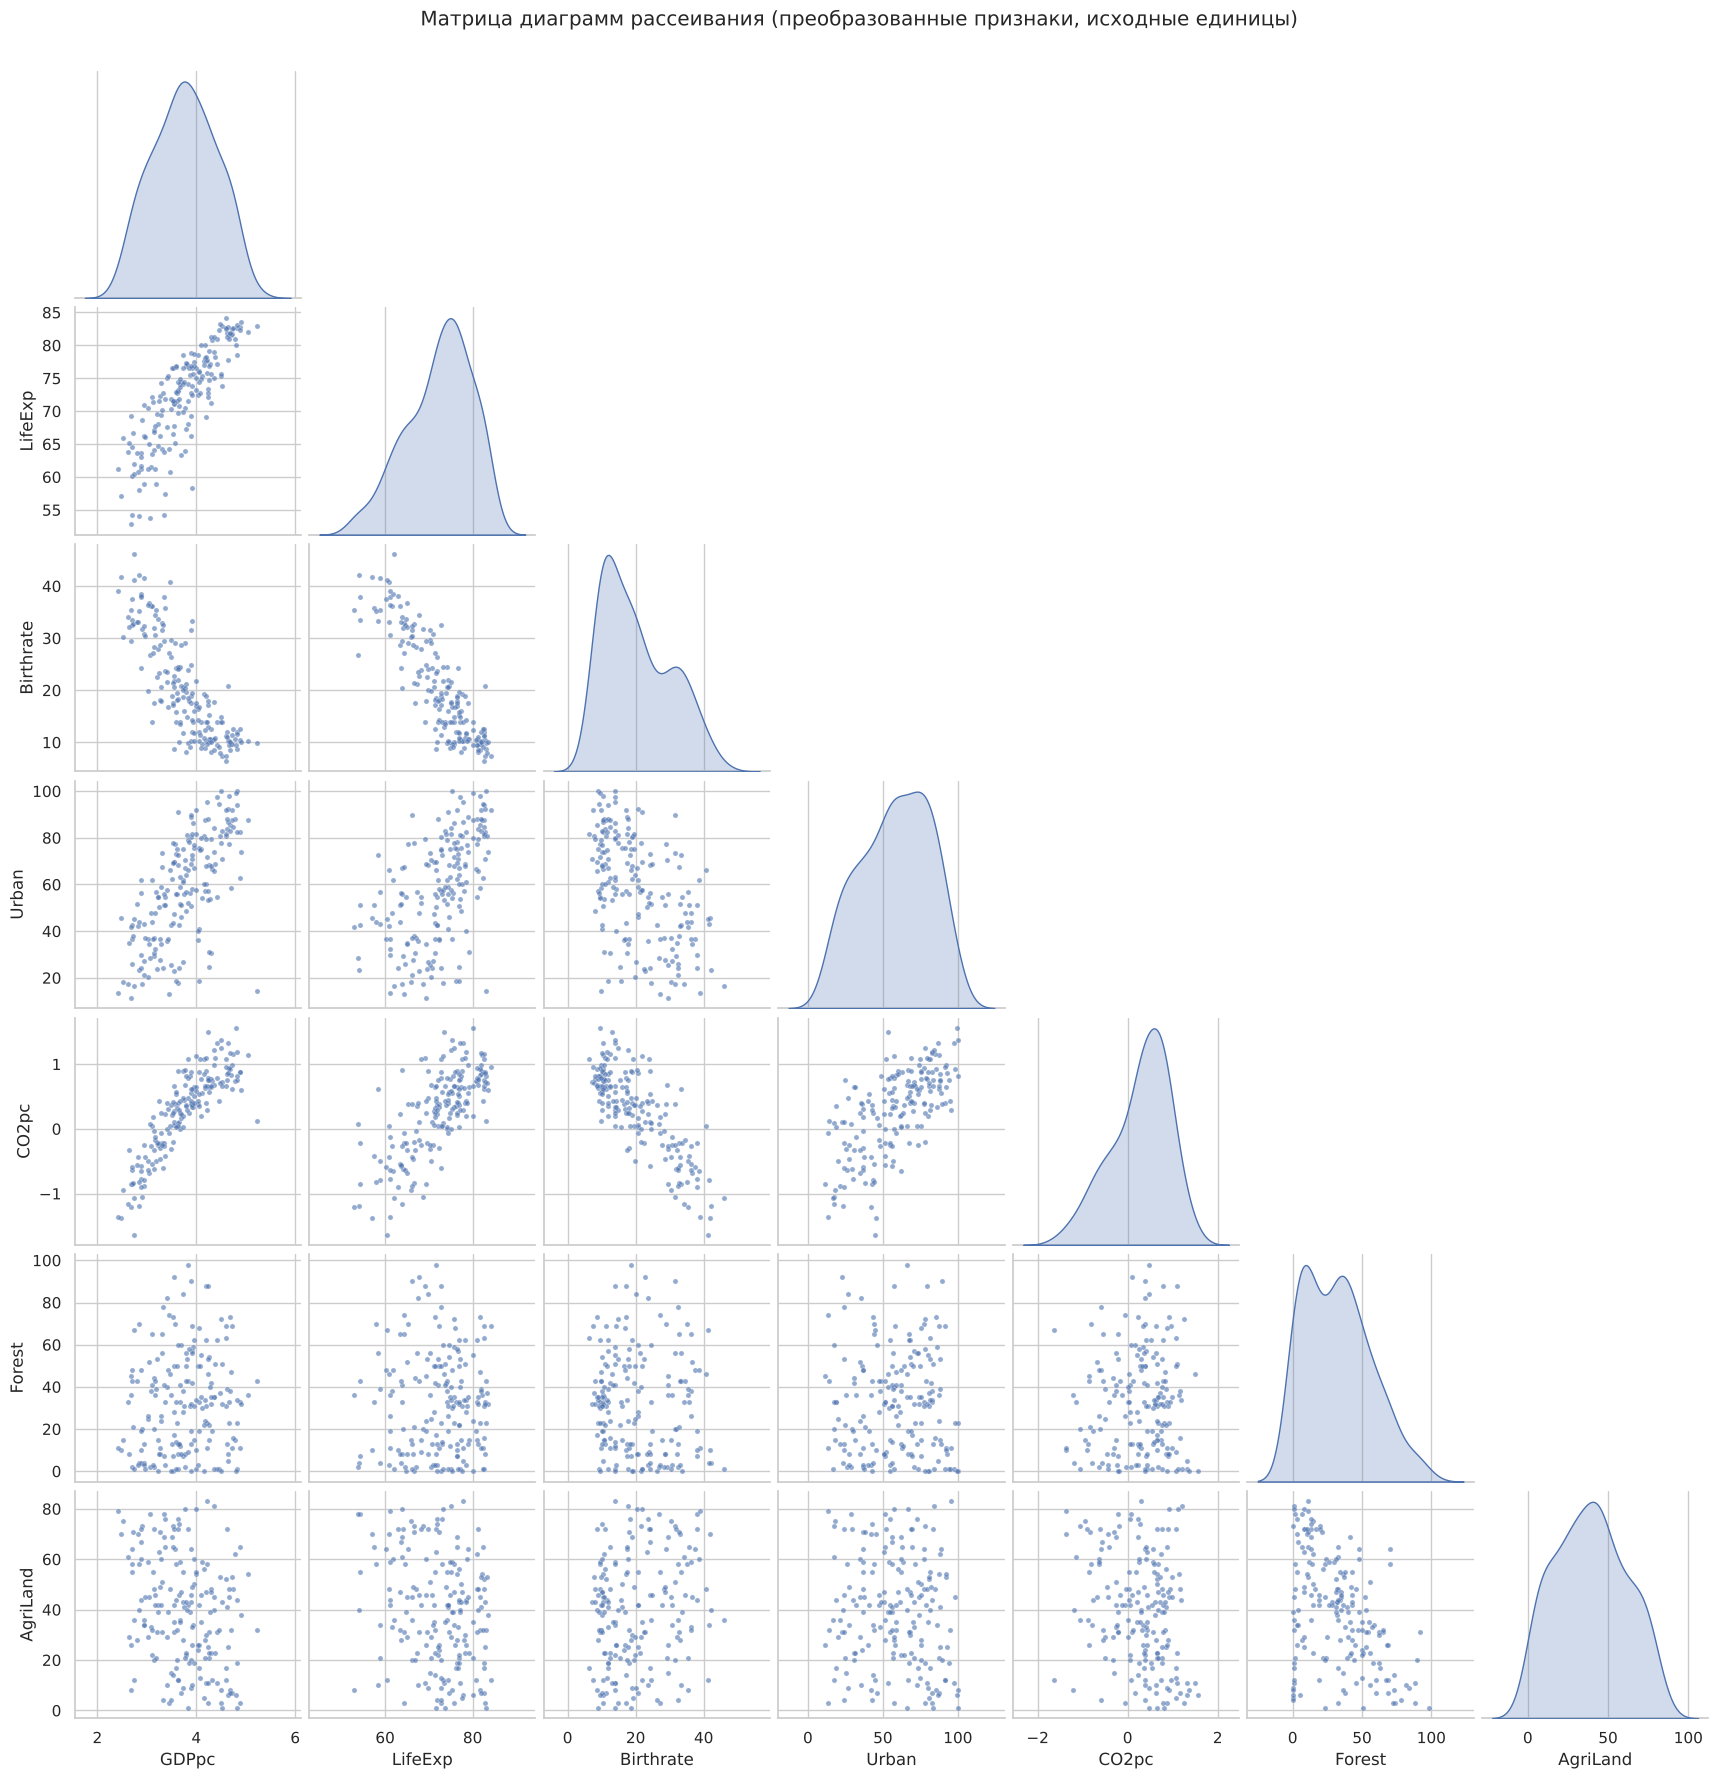

In [9]:
g = sns.pairplot(df[FEATURES], diag_kind="kde", corner=True, plot_kws={"s": 14, "alpha": 0.6, "color": "#4C72B0"},
                 diag_kws={"color": "#4C72B0"})
g.fig.suptitle("Матрица диаграмм рассеивания (преобразованные признаки, исходные единицы)", y=1.02)
plt.show()


**Пояснение к блоку кода.** Строим матрицу диаграмм рассеивания (`pairplot`, нижний треугольник): на диагонали — оценки плотности каждого признака, вне диагонали — диаграммы для каждой пары признаков. Цель — визуально оценить предполагаемое число кластеров, их форму, размер и плотность.

**Вывод по графикам.** Диаграммы пар из блока развития (`GDPpc`, `LifeExp`, `Birthrate`, `CO2pc`) показывают **одно вытянутое облако вдоль диагонали**: от «низкий ВВП — низкая продолжительность жизни — высокая рождаемость» к «высокий ВВП — долгая жизнь — низкая рождаемость». Внутри облака есть неоднородность по плотности (на графике `GDPpc`–`Birthrate` заметно сгущение у высокого ВВП и низкой рождаемости и менее плотная «ветвь» бедных стран; рождаемость и `Forest` двугорбые), но **явного провала (пустого промежутка) между группами нет** — страны образуют непрерывный градиент. Пары с `Forest` и `AgriLand` почти не показывают структуры (облака округлые, без связи с развитием), лишь между собой эти признаки связаны отрицательно. Поэтому предполагаемое число кластеров — **небольшое (2–4)**: грубое деление «менее развитые — более развитые», возможно с выделением промежуточных групп; чёткие компактные «острова» как в учебных данных ожидать не стоит. Форма кластеров — вытянутая вдоль оси развития (не строго сферическая), размеры различаются, границы размыты.

**Аргументация выбора методов.** Исходя из формы, размера и плотности групп выбраны:

- **K-means** — быстрый, даёт интерпретируемые центры, минимизирует сумму квадратов внутрикластерных расстояний; предположения метода (компактные выпуклые кластеры сопоставимого размера) выполняются лишь приближённо, но для разбиения непрерывного облака на части он подходит естественно (по сути, это квантование градиента);
- **иерархическая агломеративная кластеризация (метод Уорда)** — тот же критерий (внутрикластерная дисперсия), но другой алгоритм: не зависит от случайной инициализации, даёт дендрограмму, по которой независимо от K-means можно оценить число кластеров; два метода с единым критерием, но разной процедурой позволяют проверить, насколько результат зависит от алгоритма.

Не выбраны: **DBSCAN** — группы не разделены областями низкой плотности (облако непрерывно), поэтому при любом ε он либо объявит всё одним кластером, либо отнесёт края облака к шуму; **EM-алгоритм (GMM)** — подходил бы для вытянутых эллипсоидальных групп (в отличие от K-means он учитывает ковариации), но при сильно перекрывающихся группах и 185 объектах его оценки ковариационных матриц менее надёжны, а мягкие метки не нужны для типологии. GMM — естественное продолжение работы.

## 5. Подбор числа кластеров

Локоть (по хорде): k = 4;  максимум silhouette K-means: k = 2;  максимум silhouette Ward: k = 2
Максимум Calinski–Harabasz K-means: k = 2;  минимум Davies–Bouldin K-means: k = 2


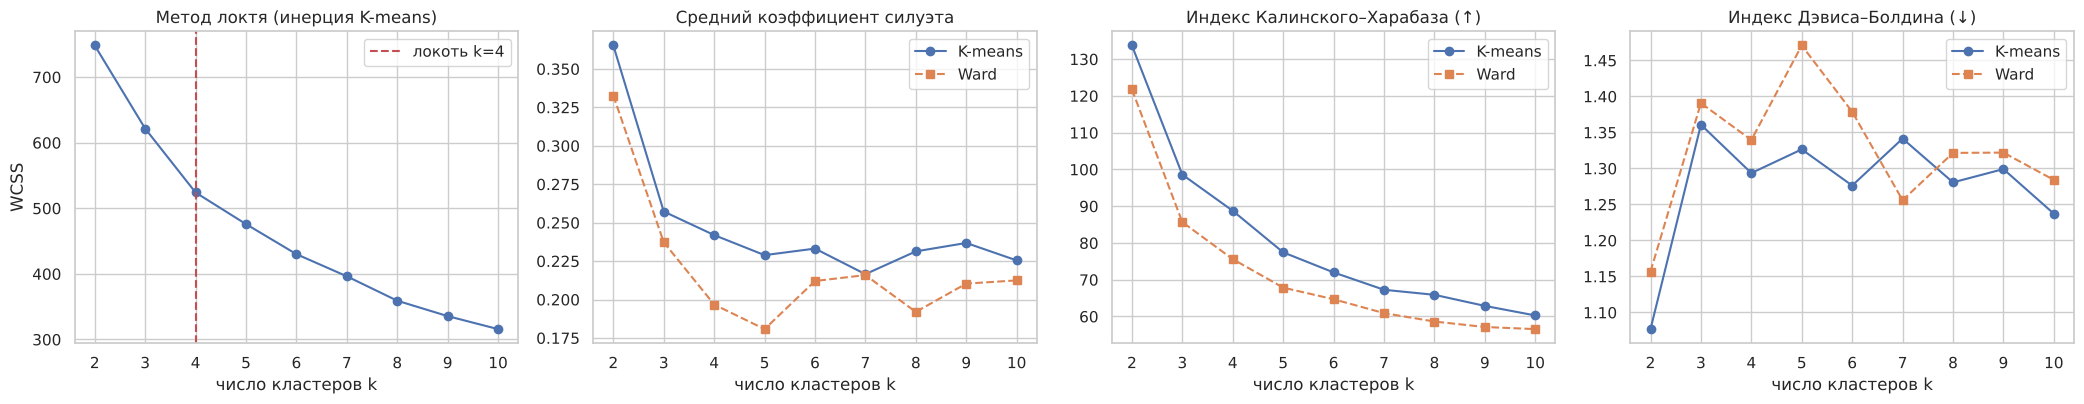

,inertia (K-means),silhouette K-means,CH K-means,DB K-means,silhouette Ward,CH Ward,DB Ward
k,,,,,,,
2,748.2236,0.3653,133.7302,1.0769,0.3327,121.7760,1.1568
3,621.5682,0.2573,98.5930,1.3607,0.2373,85.6739,1.3907
4,524.0840,0.2419,88.7490,1.2936,0.1968,75.5968,1.3395
5,475.9137,0.2289,77.4487,1.3265,0.1808,67.8576,1.4707
6,430.0926,0.2331,71.9931,1.2762,0.2121,64.6926,1.3787
7,396.3403,0.2165,67.2660,1.3414,0.2159,60.9132,1.2559
8,359.1123,0.2313,65.8975,1.2806,0.1920,58.6278,1.3216
9,335.6399,0.2368,62.8826,1.2991,0.2104,57.1398,1.3220
10,315.8221,0.2255,60.2857,1.2372,0.2125,56.5639,1.2841


In [10]:
KS = list(range(2, 11))
rows = []
for k in KS:
    km_ = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    rows.append({"k": k, "inertia (K-means)": km_.inertia_,
                 "silhouette K-means": silhouette_score(X, km_.labels_),
                 "CH K-means": calinski_harabasz_score(X, km_.labels_),
                 "DB K-means": davies_bouldin_score(X, km_.labels_),
                 "silhouette Ward": silhouette_score(X, ag.labels_),
                 "CH Ward": calinski_harabasz_score(X, ag.labels_),
                 "DB Ward": davies_bouldin_score(X, ag.labels_)})
sel = pd.DataFrame(rows).set_index("k")

# «локоть» по максимальному расстоянию от точки кривой до хорды, соединяющей концы кривой
def elbow_k(ks, y):
    ks, y = np.asarray(ks, float), np.asarray(y, float)
    p1, p2 = np.array([ks[0], y[0]]), np.array([ks[-1], y[-1]])
    v = (p2 - p1) / np.linalg.norm(p2 - p1)
    pts = np.c_[ks, y] - p1
    dist = np.abs(pts[:, 0] * v[1] - pts[:, 1] * v[0])
    return int(ks[np.argmax(dist)]), dist

K_ELBOW, elbow_dist = elbow_k(KS, sel["inertia (K-means)"])
K_KM = int(sel["silhouette K-means"].idxmax())
K_HC = int(sel["silhouette Ward"].idxmax())
K_ALT = K_ELBOW                                  # детализирующее значение k — по «локтю» (разбирается дополнительно)
print(f"Локоть (по хорде): k = {K_ELBOW};  максимум silhouette K-means: k = {K_KM};  максимум silhouette Ward: k = {K_HC}")
print(f"Максимум Calinski–Harabasz K-means: k = {int(sel['CH K-means'].idxmax())};  минимум Davies–Bouldin K-means: k = {int(sel['DB K-means'].idxmin())}")

fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
axes[0].plot(KS, sel["inertia (K-means)"], "o-", color="#4C72B0"); axes[0].axvline(K_ELBOW, color="#C44E52", ls="--", label=f"локоть k={K_ELBOW}")
axes[0].set_title("Метод локтя (инерция K-means)"); axes[0].set_ylabel("WCSS"); axes[0].legend()
axes[1].plot(KS, sel["silhouette K-means"], "o-", label="K-means"); axes[1].plot(KS, sel["silhouette Ward"], "s--", label="Ward")
axes[1].set_title("Средний коэффициент силуэта"); axes[1].legend()
axes[2].plot(KS, sel["CH K-means"], "o-", label="K-means"); axes[2].plot(KS, sel["CH Ward"], "s--", label="Ward")
axes[2].set_title("Индекс Калинского–Харабаза (↑)"); axes[2].legend()
axes[3].plot(KS, sel["DB K-means"], "o-", label="K-means"); axes[3].plot(KS, sel["DB Ward"], "s--", label="Ward")
axes[3].set_title("Индекс Дэвиса–Болдина (↓)"); axes[3].legend()
for ax in axes: ax.set_xlabel("число кластеров k"); ax.set_xticks(KS)
plt.tight_layout(); plt.show()
sel


**Пояснение к блоку кода.** Для *k* = 2…10 обучаем K-means (`n_init=10`) и иерархическую кластеризацию (Уорд) и считаем: инерцию (WCSS) для метода локтя, средний коэффициент силуэта, индекс Калинского–Харабаза (CH, чем больше, тем лучше) и индекс Дэвиса–Болдина (DB, чем меньше, тем лучше). «Локоть» определяется автоматически как точка кривой инерции, наиболее удалённая от хорды, соединяющей её концы.

**Вывод по графикам и таблице.** Кривая инерции убывает плавно (748 → 622 → 524 → 476 → 430 …), чёткого «излома» нет; автоматический критерий указывает *k* = 4, но он выбран по форме кривой и **метод локтя неоднозначен**: после *k* = 2 каждое дополнительное деление даёт примерно одинаковое уменьшение инерции. Средний силуэт K-means **максимален при *k* = 2 (0.365)**; при *k* ≥ 3 он падает до 0.22–0.26 и дальше почти не меняется (0.258 при 3; 0.242 при 4; 0.233 при 6). Для метода Уорда максимум тоже при *k* = 2 (0.333; при *k* = 3 — 0.237, при *k* = 4 — 0.197). Индекс Калинского–Харабаза у обоих методов максимален при *k* = 2 (133.7 для K-means и 121.8 для Уорда), индекс Дэвиса–Болдина минимален при *k* = 2 (1.077 и 1.157). Итог: **все три внутренних критерия сходятся на *k* = 2 для обоих методов**. Важная оговорка: значения силуэта 0.33–0.37 соответствуют, по шкале Кауфмана и Руссо, лишь **слабой** кластерной структуре (0.26–0.50), а при *k* ≥ 3 силуэт ≤ 0.26 — практически нет значимой структуры. Это согласуется с видом данных: непрерывный градиент статистически лучше всего «режется» пополам, а более детальные разбиения (локоть, *k* = 4) — это удобная типология, но не естественные группы. Поэтому основной анализ ведётся при *k* = 2, а *k* = 4 разобран дополнительно (раздел 10).

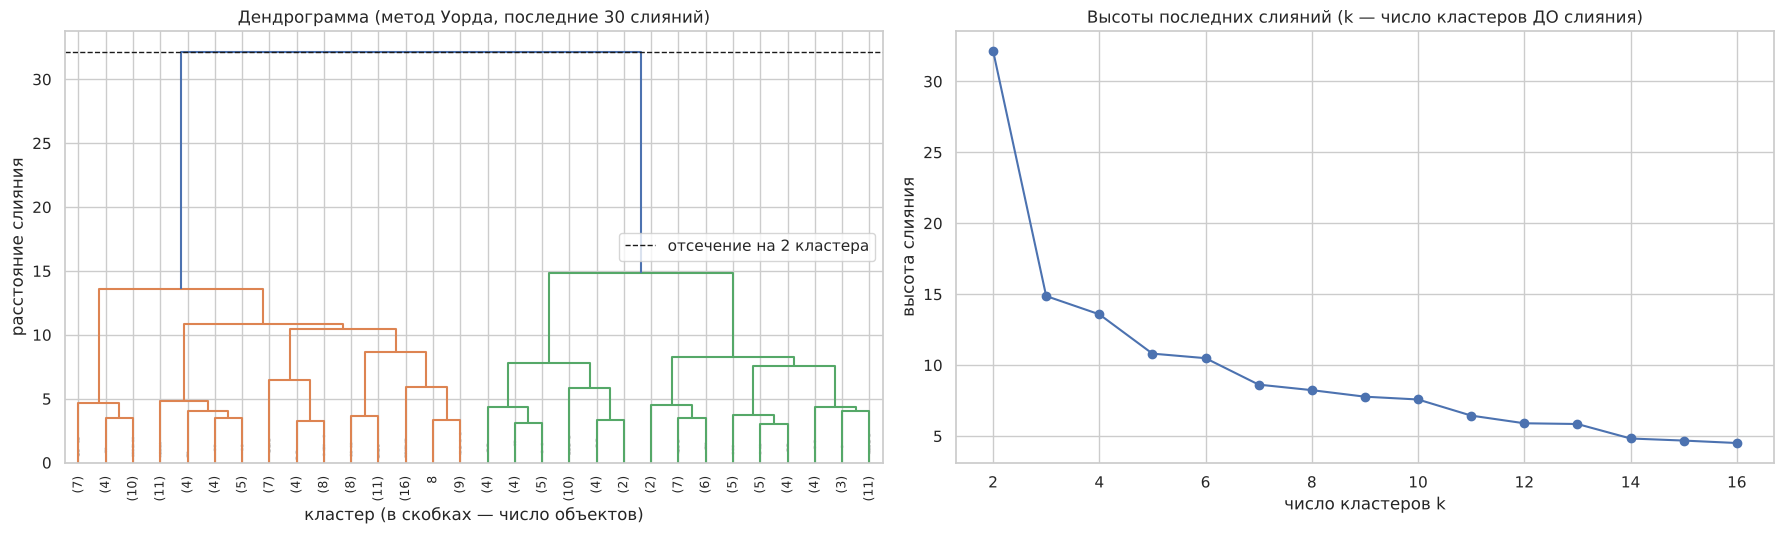

k,2,3,4,5,6,7,8,9,10,11
высота слияния k→k−1,32.1692,14.8695,13.5814,10.8106,10.4901,8.6255,8.2358,7.7753,7.5775,6.4422
запас по высоте для k кластеров,17.2997,1.2881,2.7708,0.3205,1.8646,0.3897,0.4605,0.1978,1.1353,NaN


In [11]:
Z = linkage(X, method="ward")
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True,
           color_threshold=Z[-(K_HC - 1), 2] - 1e-9, ax=axes[0])
axes[0].axhline(Z[-(K_HC - 1), 2] - 1e-9, color="k", ls="--", lw=1, label=f"отсечение на {K_HC} кластера")
axes[0].set_title("Дендрограмма (метод Уорда, последние 30 слияний)"); axes[0].set_xlabel("кластер (в скобках — число объектов)")
axes[0].set_ylabel("расстояние слияния"); axes[0].legend()

heights = Z[:, 2][::-1][:15]                       # высоты 15 последних слияний
axes[1].plot(range(2, 2 + len(heights)), heights, "o-", color="#4C72B0")
axes[1].set_title("Высоты последних слияний (k — число кластеров ДО слияния)")
axes[1].set_xlabel("число кластеров k"); axes[1].set_ylabel("высота слияния")
plt.tight_layout(); plt.show()

gap = pd.DataFrame({"k": range(2, 12), "высота слияния k→k−1": heights[:10]}).set_index("k")
gap["запас по высоте для k кластеров"] = gap["высота слияния k→k−1"] - gap["высота слияния k→k−1"].shift(-1)   # на сколько можно сдвинуть порог, не меняя разбиение на k кластеров
gap.T


**Пояснение к блоку кода.** Строим дендрограмму метода Уорда (показаны последние 30 слияний; в скобках — число объектов в «свёрнутой» ветви) и график высот слияний. Число кластеров определяется по самому длинному интервалу высот, в котором разбиение не меняется: для *k* кластеров порог можно двигать между высотой слияния (*k*+1 → *k*) и высотой слияния (*k* → *k*−1); таблица показывает размер такого «запаса».

**Вывод по графикам.** Самый большой запас по высоте у ***k* = 2 (≈ 17.30)**: последнее слияние происходит на высоте 32.2, а предыдущее — на 14.9, т.е. две крупные ветви объединяются «дорого», и разбиение на две части — самое устойчивое по дендрограмме. Далее по величине запаса идёт ***k* = 4 (≈ 2.77)**, затем *k* = 6 (≈ 1.86); для *k* = 3 запас 1.29, а для *k* = 5, 7, 8, 9 — 0.2–0.5, т.е. эти разбиения неустойчивы (порог слабо отличается от соседних слияний). Запас при *k* = 2 в **6 раз больше**, чем у ближайшего конкурента (*k* = 4), поэтому дендрограмма однозначно подтверждает *k* = 2; а *k* = 4 — второй по обоснованности вариант, что согласуется с «локтем» (также *k* = 4). Следует помнить, что запас по высоте измеряет только то, насколько последнее слияние «дороже» предыдущих; он не говорит о том, есть ли между ветвями провал плотности (его нет — см. раздел 4).

k = 2: средние силуэты кластеров по номерам: [0.34, 0.38] | размеры: [67, 118]
k = 3: средние силуэты кластеров по номерам: [0.24, 0.21, 0.32] | размеры: [91, 42, 52]


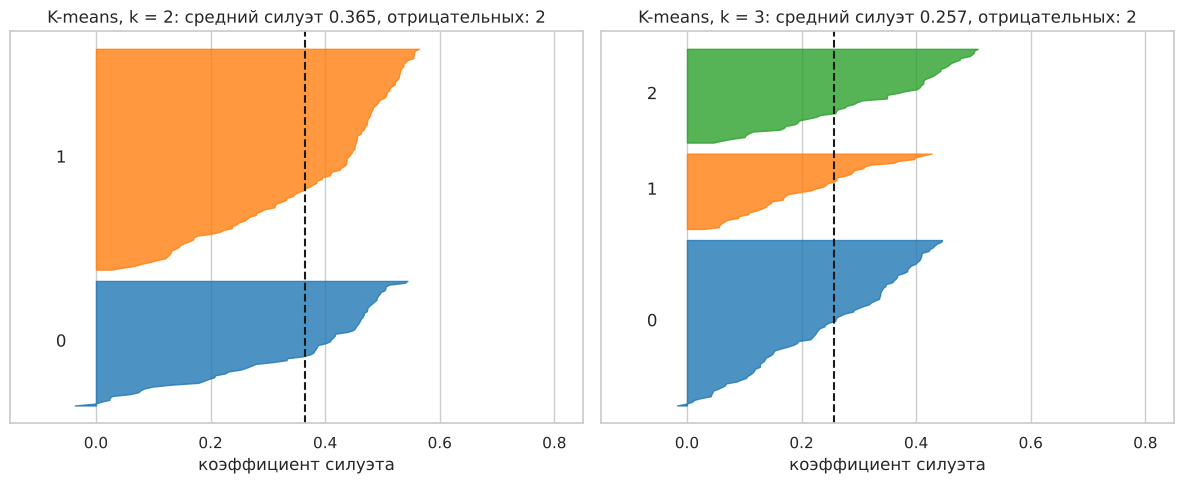

In [12]:
ks_show = sorted({max(2, K_KM - 1), K_KM, K_KM + 1})
fig, axes = plt.subplots(1, len(ks_show), figsize=(6 * len(ks_show), 5))
for ax, k in zip(np.atleast_1d(axes), ks_show):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    s = silhouette_samples(X, lab); y0 = 5
    for c in range(k):
        sc = np.sort(s[lab == c]); ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=0.8, color=plt.cm.tab10(c))
        ax.text(-0.07, y0 + len(sc) / 2, str(c), va="center"); y0 += len(sc) + 5
    ax.axvline(s.mean(), color="k", ls="--"); ax.set_xlim(-0.15, 0.85)
    ax.set_title(f"K-means, k = {k}: средний силуэт {s.mean():.3f}, отрицательных: {(s < 0).sum()}")
    ax.set_xlabel("коэффициент силуэта"); ax.set_yticks([])
    print(f"k = {k}: средние силуэты кластеров по номерам:", [round(float(s[lab == c].mean()), 2) for c in range(k)],
          "| размеры:", np.bincount(lab).tolist())
plt.tight_layout(); plt.show()


**Пояснение к блоку кода.** Для *k* = 2 и 3 (соседние с оптимумом значения) строим силуэтные диаграммы K-means: для каждого объекта вычислен коэффициент силуэта *s* = (*b* − *a*)/max(*a*, *b*), где *a* — среднее расстояние до своего кластера, *b* — до ближайшего чужого; объекты сгруппированы по кластерам и отсортированы. Пунктир — средний силуэт. Под графиками выводятся средние силуэты и размеры кластеров.

**Вывод.** При *k* = 2 средний силуэт 0.365 (наибольший), кластеры сопоставимы по качеству (средние силуэты 0.34 и 0.38; размеры 67 и 118), отрицательных значений (объектов, вероятно попавших «не в свой» кластер) всего 2 — но заметная часть объектов имеет малый положительный силуэт (пограничные страны). При *k* = 3 средний силуэт падает до 0.257, а средние силуэты кластеров — 0.24, 0.21 и 0.32 (размеры 91, 42, 52): два из трёх кластеров очень размыты, т.е. третий кластер возникает как «срединная полоса» градиента, а не как отдельная группа. Выбираем **k = 2 для обоих методов** (то же значение даёт автоматический выбор в коде).

## 6. Кластеризация двумя методами

In [13]:
km = KMeans(n_clusters=K_KM, n_init=10, random_state=SEED).fit(X)
hc = AgglomerativeClustering(n_clusters=K_HC, linkage="ward").fit(X)

# Для удобства сравнения нумеруем кластеры по возрастанию медианного ВВП на душу (метки алгоритмов произвольны)
def relabel(labels, ref=df["GDPpc"].values):
    order = pd.Series(ref).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.vectorize(mapping.get)(labels)

lab_km = relabel(km.labels_)
lab_hc = relabel(hc.labels_)
df["KMeans"], df["Ward"] = lab_km, lab_hc
print(f"K-means: k = {K_KM}, итераций до сходимости: {km.n_iter_}, инерция = {km.inertia_:.2f}")
print(f"Иерархическая (Уорд): k = {K_HC}")
print("Размеры кластеров K-means:", np.bincount(lab_km).tolist())
print("Размеры кластеров Ward:   ", np.bincount(lab_hc).tolist())


K-means: k = 2, итераций до сходимости: 5, инерция = 748.22
Иерархическая (Уорд): k = 2
Размеры кластеров K-means: [67, 118]
Размеры кластеров Ward:    [76, 109]


**Пояснение к блоку кода.** Обучаем **K-means** (`KMeans`, *k* = 2, `n_init=10` — десять случайных инициализаций, берётся лучшая по инерции, чтобы не попасть в локальный минимум) и **иерархическую агломеративную кластеризацию** (`AgglomerativeClustering`, *k* = 2, `linkage="ward"`). Метки кластеров, которые алгоритмы присваивают произвольно, перенумерованы в порядке возрастания среднего log₁₀ ВВП на душу: кластер 0 — менее развитый, 1 — более развитый.

**Вывод.** K-means сошёлся за 5 итераций, итоговая инерция 748.22. Размеры кластеров K-means: **67 и 118** (36% и 64%); Уорда: **76 и 109** (41% и 59%). Вырожденных кластеров нет, размеры двух методов близки, но не одинаковы: граница между кластерами у методов проходит в разных местах непрерывного облака (подробно — в разделе 11).

## 7. Метрики качества, расстояния и компактность кластеров

In [14]:
def dunn_parts(X, labels):
    cl = np.unique(labels)
    diam = max(pdist(X[labels == c]).max() if (labels == c).sum() > 1 else 0 for c in cl)
    sep = min(cdist(X[labels == a], X[labels == b]).min() for i, a in enumerate(cl) for b in cl[i + 1:])
    return sep, diam

def dunn_index(X, labels):
    sep, diam = dunn_parts(X, labels)
    return sep / diam

def quality(X, labels):
    cl = np.unique(labels)
    cent = np.array([X[labels == c].mean(0) for c in cl])
    d_to_c = np.linalg.norm(X - cent[np.searchsorted(cl, labels)], axis=1)       # расстояние до своего центра
    cd = squareform(pdist(cent))
    return {"Silhouette (↑)": silhouette_score(X, labels),
            "Calinski–Harabasz (↑)": calinski_harabasz_score(X, labels),
            "Davies–Bouldin (↓)": davies_bouldin_score(X, labels),
            "Dunn (↑)": dunn_index(X, labels),
            "WCSS — сумма кв. расстояний до центров (↓)": float((d_to_c ** 2).sum()),
            "ср. расстояние до центра кластера": float(d_to_c.mean()),
            "ср. попарное расстояние внутри кластеров": float(np.mean(np.concatenate([pdist(X[labels == c]) for c in cl if (labels == c).sum() > 1]))),
            "мин. расстояние между центрами": float(cd[np.triu_indices(len(cl), 1)].min()),
            "ср. расстояние между центрами": float(cd[np.triu_indices(len(cl), 1)].mean())}

qual = pd.DataFrame({"K-means": quality(X, lab_km), "Ward": quality(X, lab_hc)})
display(qual)

# из чего состоит индекс Данна: минимальный зазор между кластерами / максимальный диаметр кластера
dn = pd.DataFrame({m: dict(zip(["мин. зазор между кластерами (одна пара точек)", "макс. диаметр кластера"], dunn_parts(X, l)))
                   for m, l in [("K-means", lab_km), ("Ward", lab_hc)]})
dn.loc["Dunn = зазор / диаметр"] = dn.iloc[0] / dn.iloc[1]
display(dn)

# чувствительность Dunn: пересчёт на 30 подвыборках по 90% объектов
rs = np.random.default_rng(SEED)
dun_sub = {"K-means": [], "Ward": []}
for _ in range(30):
    idx = rs.choice(len(X), int(0.9 * len(X)), replace=False)
    for m, l in [("K-means", lab_km), ("Ward", lab_hc)]:
        dun_sub[m].append(dunn_index(X[idx], l[idx]))
display(pd.DataFrame({m: {"Dunn, среднее по подвыборкам": np.mean(v), "Dunn, σ": np.std(v), "Dunn, мин.": np.min(v), "Dunn, макс.": np.max(v)}
                      for m, v in dun_sub.items()}))


,K-means,Ward
Silhouette (↑),0.3653,0.3327
Calinski–Harabasz (↑),133.7302,121.7760
Davies–Bouldin (↓),1.0769,1.1568
Dunn (↑),0.1219,0.1098
WCSS — сумма кв. расстояний до центров (↓),748.2236,777.5712
ср. расстояние до центра кластера,1.9106,1.9482
ср. попарное расстояние внутри кластеров,2.6856,2.7284
мин. расстояние между центрами,3.5769,3.3993
ср. расстояние между центрами,3.5769,3.3993


,K-means,Ward
мин. зазор между кластерами (одна пара точек),0.7289,0.7220
макс. диаметр кластера,5.9800,6.5748
Dunn = зазор / диаметр,0.1219,0.1098


,K-means,Ward
"Dunn, среднее по подвыборкам",0.1259,0.1205
"Dunn, σ",0.0065,0.0166
"Dunn, мин.",0.1219,0.1098
"Dunn, макс.",0.1439,0.1626


**Пояснение к блоку кода.** Для обоих разбиений рассчитаны **внутренние метрики** (эталонных меток нет): силуэт (↑), индекс Калинского–Харабаза (↑), индекс Дэвиса–Болдина (↓), индекс Данна (↑; отношение минимального расстояния между точками разных кластеров к максимальному диаметру кластера); **компактность** — сумма квадратов расстояний до центров (WCSS), среднее расстояние до центра своего кластера и среднее попарное расстояние внутри кластеров; **разделённость** — минимальное и среднее расстояние между центрами кластеров (при *k* = 2 они совпадают, так как центров два). Все расстояния евклидовы, в единицах стандартизованных признаков. Отдельно раскрыт состав индекса Данна (числитель и знаменатель) и его чувствительность к составу выборки (30 подвыборок по 90% объектов).

**Вывод.** По силуэту (0.365 против 0.333), индексу CH (133.7 против 121.8), DB (1.077 против 1.157) и WCSS (748.2 против 777.6) K-means лучше Уорда, что естественно: он напрямую оптимизирует WCSS. Силуэт 0.33–0.37 означает **слабую** кластерную структуру: кластеры различимы, но плотно примыкают друг к другу (согласуется со статистикой Хопкинса 0.71 и диаграммами). Среднее расстояние объекта до центра своего кластера 1.91 (K-means) и 1.95 (Уорд) при расстоянии между двумя центрами 3.58 и 3.40: центры разнесены лишь примерно в **1.7–1.9 раза** дальше, чем «радиус» кластера, т.е. кластеры заметно перекрываются. Различия методов по основным метрикам — 4–11%, качество разбиений близко.

**Индекс Данна.** У K-means он **выше** (0.122 против 0.110), и его не следует использовать как основной критерий. Он равен отношению двух величин, каждая из которых определяется всего одной парой точек: минимальный зазор между кластерами почти одинаков (0.729 и 0.722) — это расстояние между двумя ближайшими странами из разных кластеров, а различие создаёт максимальный диаметр кластера (5.98 против 6.57), т.е. пара самых далёких стран внутри самого «широкого» кластера. На подвыборках по 90% объектов индекс меняется (в среднем 0.126 у K-means и 0.121 у Уорда, σ = 0.007 и 0.017): разброс у Уорда в 2.5 раза больше, а размах значений (0.110–0.163 у Уорда) перекрывает значения K-means. То есть при соприкасающихся группах индекс близок к небольшому числу, определяется парой точек и надёжного различия между методами не показывает. Основными остаются силуэт, CH и DB.

K-means — компактность кластеров (стандартизованные признаки):


,размер,"доля, %",ср. расст. до центра,макс. расст. до центра,диаметр,ср. силуэт
кластер,,,,,,
0,67,36.2162,1.9820,3.3067,5.9800,0.3378
1,118,63.7838,1.8700,3.5113,5.7410,0.3808


Ward — компактность кластеров:


,размер,"доля, %",ср. расст. до центра,макс. расст. до центра,диаметр,ср. силуэт
кластер,,,,,,
0,76,41.0811,2.0670,3.6564,6.5748,0.2852
1,109,58.9189,1.8653,3.4570,5.7410,0.3658


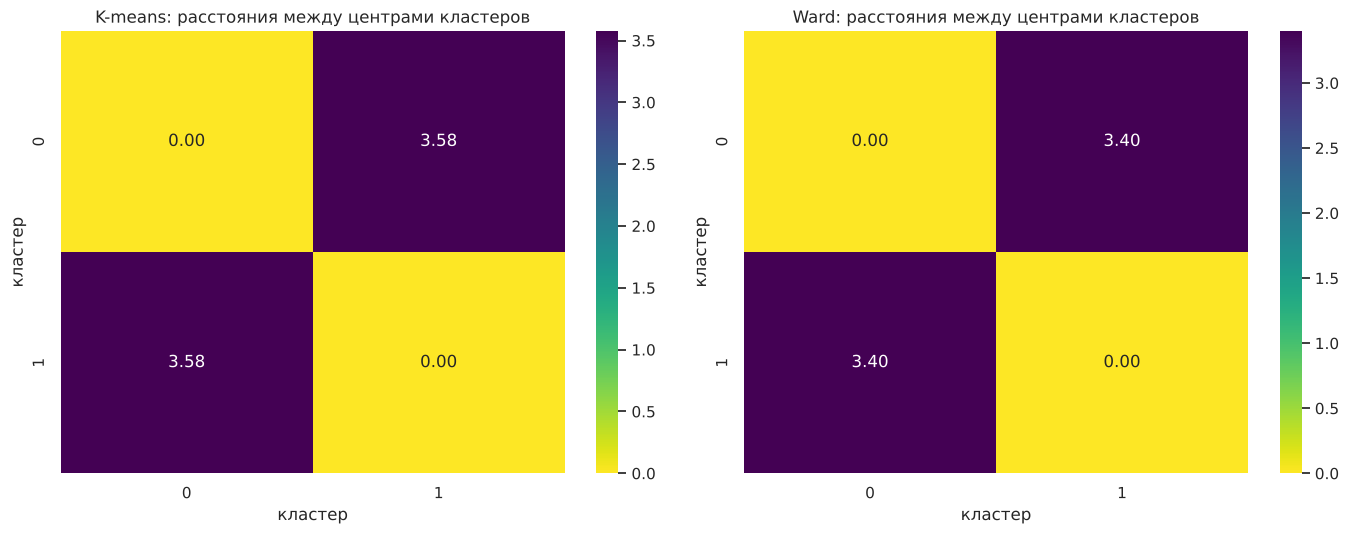

In [15]:
def per_cluster(X, labels):
    rows = []
    s = silhouette_samples(X, labels)
    for c in np.unique(labels):
        P = X[labels == c]; mu = P.mean(0)
        d = np.linalg.norm(P - mu, axis=1)
        rows.append({"кластер": c, "размер": len(P), "доля, %": len(P) / len(X) * 100,
                     "ср. расст. до центра": d.mean(), "макс. расст. до центра": d.max(),
                     "диаметр": pdist(P).max() if len(P) > 1 else 0.0, "ср. силуэт": s[labels == c].mean()})
    return pd.DataFrame(rows).set_index("кластер")

print("K-means — компактность кластеров (стандартизованные признаки):")
display(per_cluster(X, lab_km))
print("Ward — компактность кластеров:")
display(per_cluster(X, lab_hc))

def centroid_dist(labels):
    cl = np.unique(labels); cent = np.array([X[labels == c].mean(0) for c in cl])
    return pd.DataFrame(squareform(pdist(cent)), index=cl, columns=cl)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, lab, name in zip(axes, [lab_km, lab_hc], ["K-means", "Ward"]):
    sns.heatmap(centroid_dist(lab), annot=True, fmt=".2f", cmap="viridis_r", ax=ax)
    ax.set_title(f"{name}: расстояния между центрами кластеров"); ax.set_xlabel("кластер"); ax.set_ylabel("кластер")
plt.tight_layout(); plt.show()


**Пояснение к блоку кода.** Для каждого кластера считаются размер, доля, среднее и максимальное расстояние до центра, диаметр (наибольшее попарное расстояние) и средний силуэт — это характеристики компактности. Тепловые карты показывают матрицы расстояний между центрами кластеров (в палитре `viridis_r`).

**Вывод.** *K-means:* кластер 1 (более развитые страны, 118) компактнее — среднее расстояние до центра 1.87, силуэт 0.38; кластер 0 (менее развитые, 67) **более размытый** — 1.98 и 0.34 (диаметры 5.98 и 5.74). *Ward:* картина та же, но контраст сильнее: кластер 0 (76 стран) — самый размытый (среднее расстояние 2.07, диаметр 6.57, силуэт **0.285**), кластер 1 (109) — 1.87 и 0.366; число объектов с отрицательным силуэтом у Уорда 16 против 2 у K-means. Размытость «менее развитого» кластера объясняется составом: он включает как самые бедные страны, так и страны на границе среднего дохода. Расстояние между центрами 3.58 (K-means) и 3.40 (Уорд) заметно меньше диаметров кластеров (5.7–6.6), поэтому кластеры перекрываются на периферии.

**Внешние метрики.** Истинного разбиения на классы в данных нет, поэтому внешние метрики рассчитаны в блоке сравнения методов (раздел 11) как метрики **согласованности двух разбиений**: K-means против Уорда и каждый из методов против справочной группировки по регионам. Регион — не «истинные классы»: он лишь частично отражает уровень развития, и высокое значение метрики против региона не было бы доказательством качества кластеризации.

## 8. Центры кластеров и интерпретация

K-means — типичные значения (медианы) по кластерам, исходные единицы:


,размер,"ВВП на душу, $","Продолжительность жизни, лет","Рождаемость, ‰","Городское население, %","CO2 на душу, т","Леса, %","Сельхозземли, %",главный регион,"его доля, %"
0,67,"1,394.0000",64.7000,31.8800,36.9070,0.4671,25.0000,46.0000,SUB-SAHARAN AFRICA,62.5000
1,118,"12,283.0000",76.5500,13.2050,70.7610,4.5425,33.0000,34.5000,LATIN AMER. & CARIB,26.7241


Ward — типичные значения (медианы) по кластерам, исходные единицы:


,размер,"ВВП на душу, $","Продолжительность жизни, лет","Рождаемость, ‰","Городское население, %","CO2 на душу, т","Леса, %","Сельхозземли, %",главный регион,"его доля, %"
0,76,"1,455.5000",66.0000,30.7200,42.0090,0.5451,34.5000,42.0000,SUB-SAHARAN AFRICA,56.9444
1,109,"14,853.0000",76.8000,12.4300,73.1890,4.7463,31.0000,39.0000,LATIN AMER. & CARIB,23.1481


Центры K-means в единицах преобразованных признаков (log10 для GDPpc и CO2pc):


,GDPpc,LifeExp,Birthrate,Urban,CO2pc,Forest,AgriLand
0,3.1042,64.7030,31.0497,39.4215,-0.4038,29.4030,45.6866
1,4.1338,76.5949,14.2830,69.1257,0.6577,33.8305,35.4661


Макс. расхождение центров sklearn и средних по кластерам: 1.4210854715202004e-14


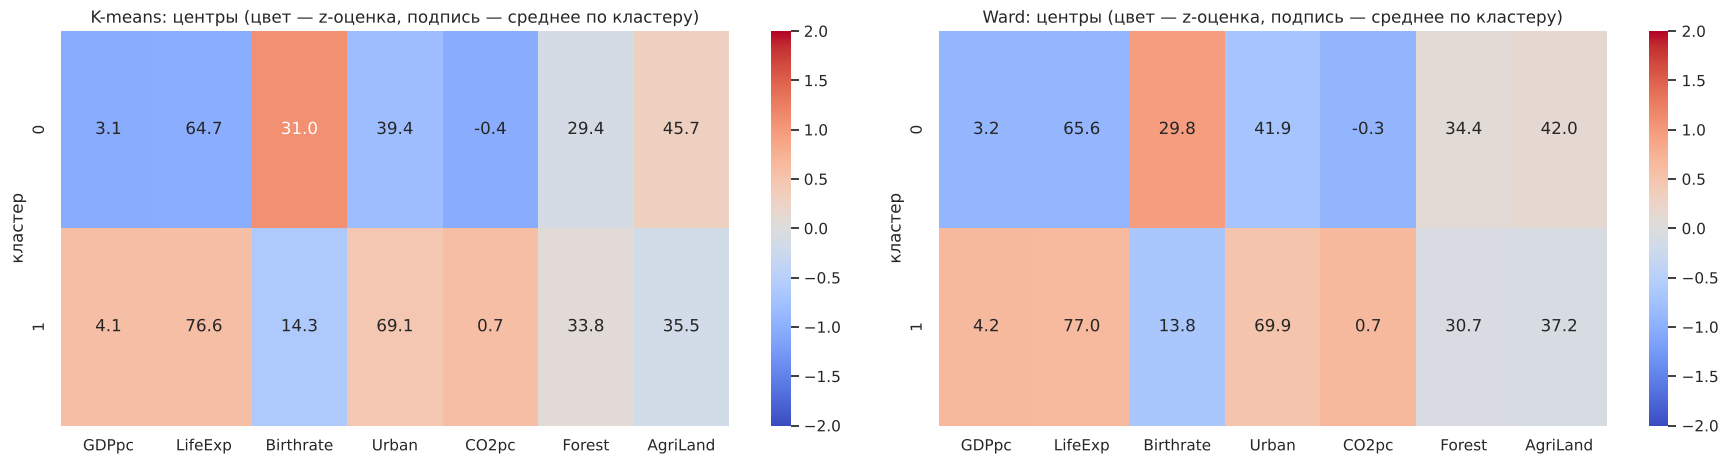

Состав кластеров K-means по регионам (число стран):


Region,ASIA (EX. NEAR EAST),BALTICS,C.W. OF IND. STATES,EASTERN EUROPE,LATIN AMER. & CARIB,NEAR EAST,NORTHERN AFRICA,NORTHERN AMERICA,OCEANIA,SUB-SAHARAN AFRICA,WESTERN EUROPE,неизвестен
кластер,,,,,,,,,,,,
0,9,0,3,0,2,2,1,0,7,40,0,3
1,15,3,9,11,31,12,4,2,4,5,20,2


Кластер 0: Eritrea, Federated States of Micronesia, Kiribati, Rwanda, Somalia, Tonga, Marshall Islands, Vanuatu, Cambodia, Djibouti, Papua New Guinea, Philippines …
Кластер 1: Austria, Denmark, Finland, Grenada, Iceland, Liechtenstein, North Korea, Norway, Saint Lucia, Singapore, Sweden, Switzerland …


In [16]:
def profile(labels):
    g = orig.groupby(labels)
    out = g.median()                                            # медианы в исходных единицах (устойчивы к хвостам)
    out.insert(0, "размер", g.size())
    top = df.groupby(labels)["Region"].agg(lambda s: s.value_counts().index[0] if s.notna().any() else "—")
    share = df.groupby(labels)["Region"].agg(lambda s: s.value_counts(normalize=True).iloc[0] * 100 if s.notna().any() else np.nan)
    out["главный регион"] = top; out["его доля, %"] = share
    return out

print("K-means — типичные значения (медианы) по кластерам, исходные единицы:")
prof_km = profile(lab_km); display(prof_km)
print("Ward — типичные значения (медианы) по кластерам, исходные единицы:")
prof_hc = profile(lab_hc); display(prof_hc)

# центры K-means: проверка, что центры sklearn (после inverse_transform) совпадают со средними по кластерам
centers_orig = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=FEATURES)
centers_orig.index = [pd.Series(lab_km)[km.labels_ == i].iloc[0] for i in range(K_KM)]
centers_orig = centers_orig.sort_index()
print("Центры K-means в единицах преобразованных признаков (log10 для GDPpc и CO2pc):")
display(centers_orig)
print("Макс. расхождение центров sklearn и средних по кластерам:", float(np.abs(centers_orig.values - df.groupby(lab_km)[FEATURES].mean().values).max()))

fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
for ax, lab, p, name in zip(axes, [lab_km, lab_hc], [prof_km, prof_hc], ["K-means", "Ward"]):
    m = df.groupby(lab)[FEATURES].mean()
    z = (m - df[FEATURES].mean()) / df[FEATURES].std()
    sns.heatmap(z, annot=m.round(1), fmt="", cmap="coolwarm", center=0, vmin=-2, vmax=2, ax=ax)
    ax.set_title(f"{name}: центры (цвет — z-оценка, подпись — среднее по кластеру)"); ax.set_ylabel("кластер")
plt.tight_layout(); plt.show()

print("Состав кластеров K-means по регионам (число стран):")
display(pd.crosstab(pd.Series(lab_km, name="кластер"), df["Region"].fillna("неизвестен")))
for c in range(K_KM):
    print(f"Кластер {c}:", ", ".join(df.loc[lab_km == c, "Country"].head(12)), "…" if (lab_km == c).sum() > 12 else "")


**Пояснение к блоку кода.** Таблицы показывают типичные значения (медианы в исходных единицах — они не искажаются хвостами) по кластерам K-means и Уорда, размер кластера, главный регион и его долю среди стран с известным регионом. Затем выведены центры K-means в единицах преобразованных признаков (`scaler.inverse_transform` — для `GDPpc` и `CO2pc` это log₁₀) и проверка, что они совпадают со средними по кластерам (расхождение ≈ 10⁻¹⁴). Тепловые карты: цвет — стандартизованное отклонение среднего по кластеру от среднего по выборке (красное — выше, синее — ниже), подпись — среднее значение. Ниже — состав кластеров K-means по регионам и примеры стран.

**Вывод — содержательная интерпретация групп (по K-means, *k* = 2).**

| Кластер | Размер | ВВП на душу, $ (медиана) | Продолж. жизни, лет | Рождаемость, ‰ | Городское население, % | CO₂ на душу, т | Лес / с.-х. земли, % | Описание |
|---|---|---|---|---|---|---|---|---|
| 0 | 67 | ≈ 1 400 | ≈ 64.7 | ≈ 31.9 | ≈ 37 | ≈ 0.47 | 25 / 46 | **«Менее развитые страны»**: низкий доход, короткая жизнь, высокая рождаемость, преобладает сельское население; 62.5% стран с известным регионом — Африка к югу от Сахары (40 стран), далее Азия (9) и Океания (7) |
| 1 | 118 | ≈ 12 300 | ≈ 76.6 | ≈ 13.2 | ≈ 71 | ≈ 4.5 | 33 / 35 | **«Более развитые и среднеразвитые страны»**: от стран со средним доходом (Латинская Америка — 31, Ближний Восток — 12, Восточная Европа — 11) до богатых (Западная Европа — 20); 5 стран Африки к югу от Сахары попали сюда по высоким показателям |

Структура землепользования (`Forest`, `AgriLand`) различает кластеры слабо (доля лесов 25% против 33%, сельхозземель 46% против 35%): ожидаемо, так как эти признаки почти не связаны с развитием (раздел 1). Кластеры Уорда имеют качественно тот же профиль (кластер 0: 76 стран, ≈ 1 460 $, 66.0 лет, рождаемость 30.7‰, главный регион — Африка к югу от Сахары, 57%; кластер 1: 109 стран, ≈ 14 850 $, 76.8 лет, 12.4‰), но граница сдвинута: Уорд относит к «менее развитым» ещё 13 стран среднего уровня (разбор — в разделе 11). Регион и кластер связаны, но не тождественны: латиноамериканские, восточноевропейские и западноевропейские страны почти целиком в кластере 1, африканские — в основном в кластере 0 (40 из 45 с известным регионом). Пример пограничной страны — Габон (ВВП ≈ 7 600 $, но рождаемость 31.6‰): в K-means он в кластере 1, а в Уорде — в кластере 0.

## 9. Визуализация кластеров

Доля дисперсии PC1, PC2: [0.58  0.198] суммарно: 0.778 | не отражено проекцией: 0.222


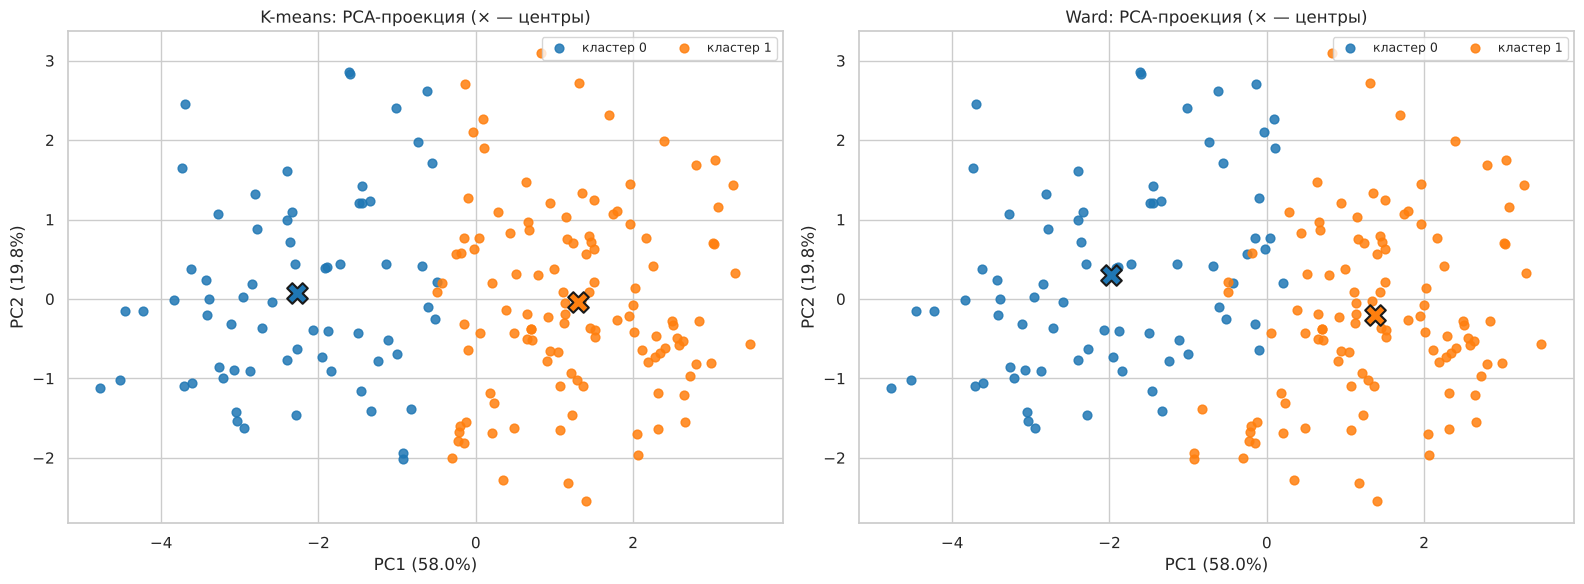

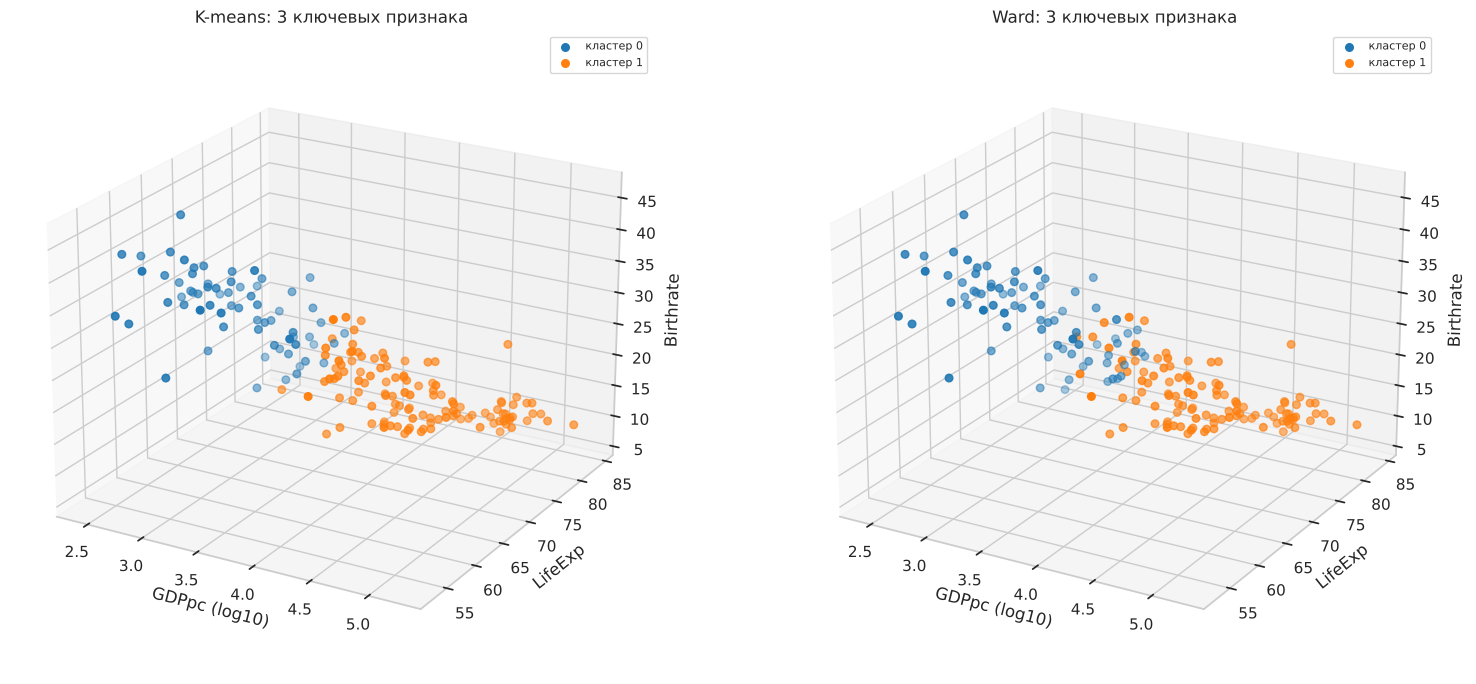

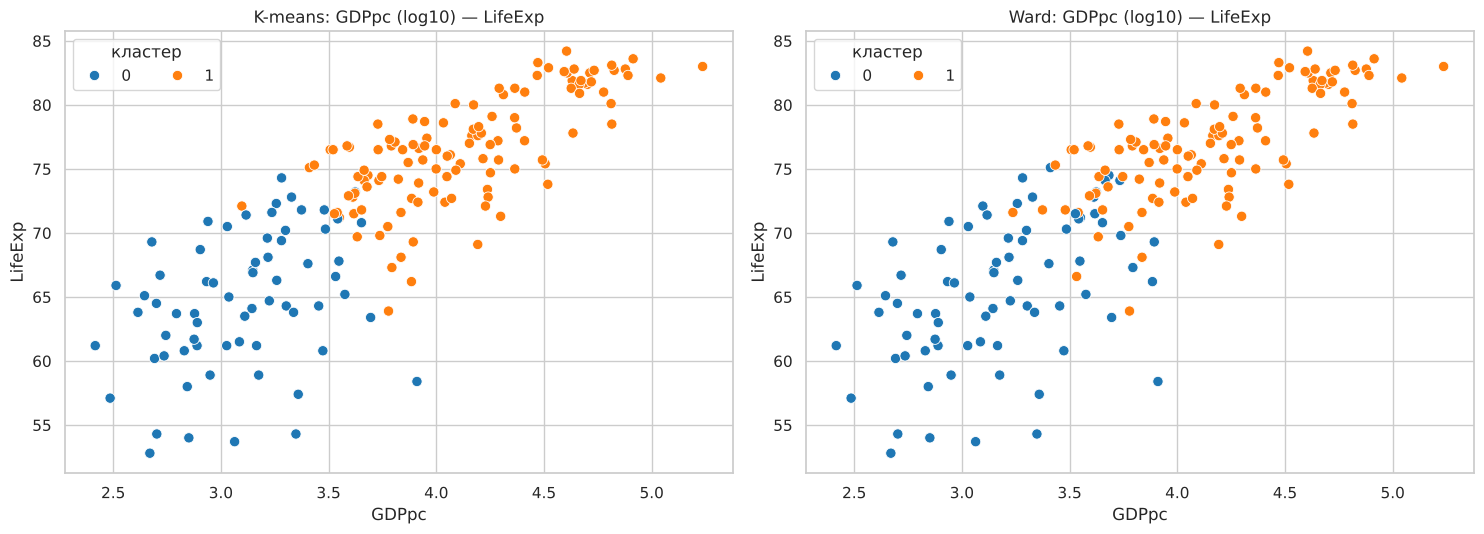

In [17]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X)
evr = pca.explained_variance_ratio_
print("Доля дисперсии PC1, PC2:", evr.round(3), "суммарно:", evr.sum().round(3), "| не отражено проекцией:", (1 - evr.sum()).round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, lab, name in zip(axes, [lab_km, lab_hc], ["K-means", "Ward"]):
    for c in np.unique(lab):
        ax.scatter(P[lab == c, 0], P[lab == c, 1], s=40, color=plt.cm.tab10(c), alpha=0.85, label=f"кластер {c}")
        m = P[lab == c].mean(0)
        ax.scatter(*m, marker="X", s=220, color=plt.cm.tab10(c), edgecolor="k", linewidth=1.5)
    ax.set_title(f"{name}: PCA-проекция (× — центры)"); ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)"); ax.legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(16, 7))
for j, (lab, name) in enumerate(zip([lab_km, lab_hc], ["K-means", "Ward"])):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(df.loc[m, "GDPpc"], df.loc[m, "LifeExp"], df.loc[m, "Birthrate"], s=30, color=plt.cm.tab10(c), label=f"кластер {c}")
    ax.set_xlabel("GDPpc (log10)"); ax.set_ylabel("LifeExp"); ax.set_zlabel("Birthrate"); ax.set_title(f"{name}: 3 ключевых признака")
    ax.view_init(elev=22, azim=-60); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, lab, name in zip(axes, [lab_km, lab_hc], ["K-means", "Ward"]):
    sns.scatterplot(x=df["GDPpc"], y=df["LifeExp"], hue=lab, palette="tab10", s=55, ax=ax, legend="full")
    ax.set_title(f"{name}: GDPpc (log10) — LifeExp"); ax.legend(title="кластер", ncol=2)
plt.tight_layout(); plt.show()


**Пояснение к блоку кода.** Для визуализации в плоскости применяем PCA (две главные компоненты стандартизованных признаков); крестами показаны центры кластеров. Дополнительно строим трёхмерную диаграмму в трёх ключевых признаках (`GDPpc`, `LifeExp`, `Birthrate`) и плоскость `GDPpc`–`LifeExp`, раскрашенные по кластерам обоих методов.

**Вывод по графикам.** Две компоненты объясняют **77.8%** дисперсии (PC1 = 58.0%, PC2 = 19.8%): проекция отражает структуру почти точно, но **22.2% дисперсии (PC3 и далее: 7.9%, 7.8%, 3.4%, …) остаются «за кадром»**, поэтому близость точек на плоскости не гарантирует их близости в семимерном пространстве; в частности, ось PC3 — урбанизация — на графике не видна. На проекции видно **одно непрерывное облако**, а не две отдельные группы: по оси PC1 (развитие) слева — менее развитые страны, справа — более развитые, по оси PC2 (лес против сельхозземель) разброс есть у обоих кластеров примерно одинаковый. Граница между кластерами у K-means проходит примерно вертикально в районе PC1 ≈ −1…0; у Уорда кластер 0 больше (76 против 67 стран), т.е. граница сдвинута вправо, в сторону более развитых стран, а различия сводятся к полосе пограничных точек. Центры кластеров разнесены в основном по PC1; по PC2 они почти совпадают, т.е. кластеры различаются прежде всего уровнем развития. На трёхмерной диаграмме и в плоскости `GDPpc`–`LifeExp` видна та же картина — градиент без провала между группами; различия методов заметны лишь в узкой полосе средних значений ВВП (log₁₀ ВВП на душу ≈ 3.2–3.9, т.е. примерно 1.7–7.8 тыс. $).

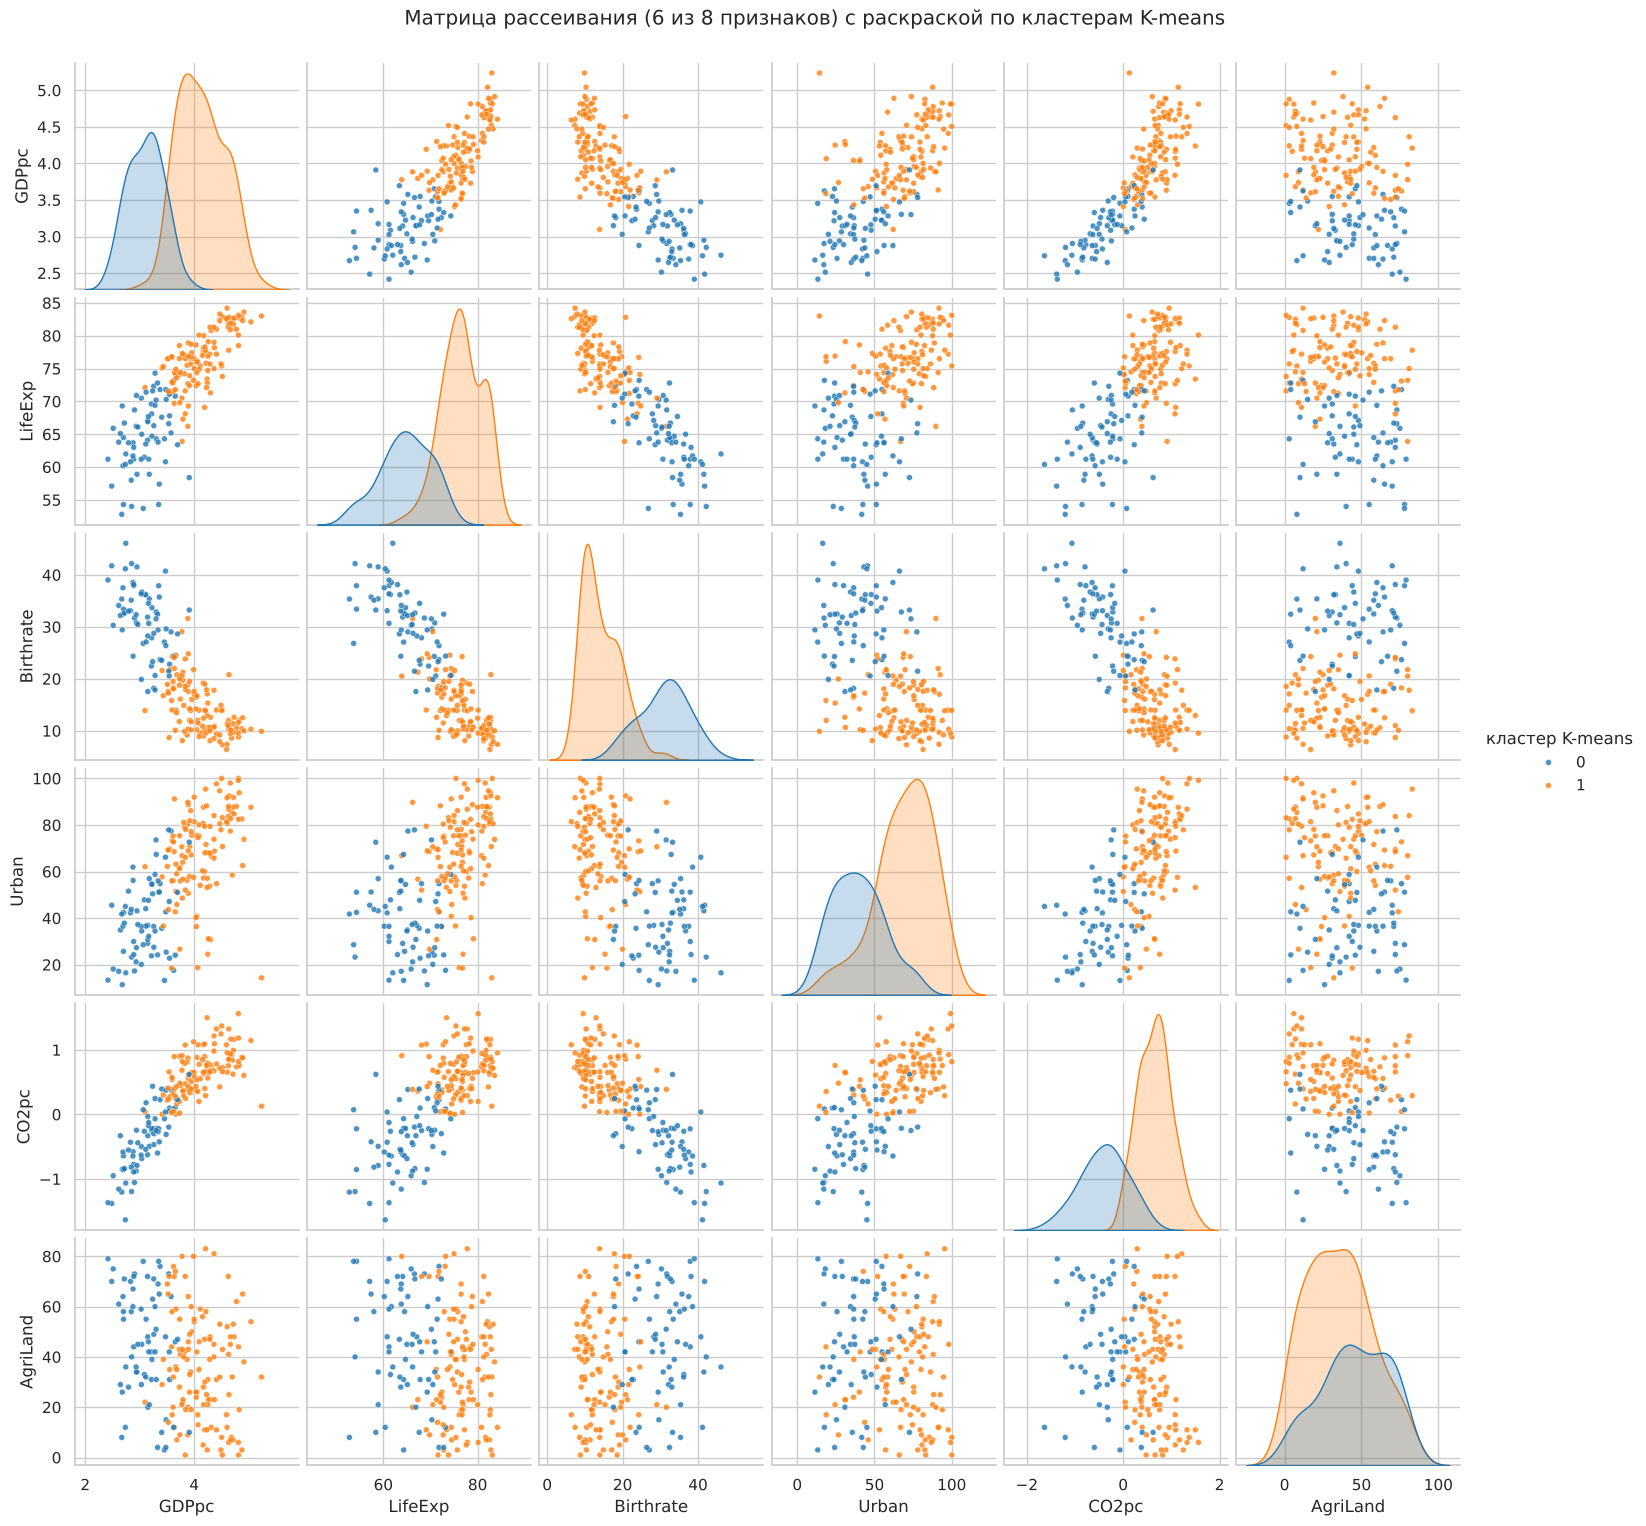

In [18]:
tmp = df[["GDPpc", "LifeExp", "Birthrate", "Urban", "CO2pc", "AgriLand"]].copy(); tmp["кластер K-means"] = lab_km
g = sns.pairplot(tmp, hue="кластер K-means", palette="tab10", diag_kind="kde", plot_kws={"s": 18, "alpha": 0.8})
g.fig.suptitle("Матрица рассеивания (6 из 8 признаков) с раскраской по кластерам K-means", y=1.02); plt.show()


**Пояснение к блоку кода.** Матрица рассеивания (шесть из семи признаков), раскрашенная по кластерам K-means: на диагонали — плотности признаков внутри каждого кластера.

**Вывод.** Кластеры чётко разделяются по признакам развития (`GDPpc`, `LifeExp`, `Birthrate`, `CO2pc`) и по `Urban` — распределения почти не пересекаются на краях и перекрываются в середине. По `AgriLand` разница небольшая (кластер 0 в среднем сильнее аграрный), по `Forest` почти нет. Это подтверждает, что двухкластерное разбиение отражает именно **уровень развития**, а структура землепользования для него вторична.

## 10. Влияние параметров и устойчивость

,ARI подвыборок (ср.),ARI подвыборок (σ),ARI между запусками n_init=1 (ср.),ARI между запусками (мин.),"inertia (n_init=1, ср.)","inertia (n_init=1, σ)"
k,,,,,,
2,0.9623,0.0281,0.9365,0.0041,760.6699,66.5488
3,0.7038,0.2233,0.6717,0.3443,627.8369,9.7677
4,0.8764,0.0807,0.7117,0.3320,534.9054,13.7151
5,0.6921,0.1191,0.5871,0.4698,485.6263,8.0765
6,0.6591,0.1931,0.5351,0.3272,444.0536,6.6209
7,0.6846,0.1080,0.5921,0.3617,407.0106,8.9760
8,0.7050,0.1135,0.6524,0.3580,374.2134,11.0447
9,0.7093,0.0982,0.6531,0.4435,348.9622,11.1552
10,0.6693,0.0973,0.6221,0.4197,327.7584,9.9622


Значения k с ARI на подвыборках < 0.90 («провалы» устойчивости): {3: 0.704, 4: 0.876, 5: 0.692, 6: 0.659, 7: 0.685, 8: 0.705, 9: 0.709, 10: 0.669}
ARI подвыборок при выбранном k = 2: 0.962 ± 0.028


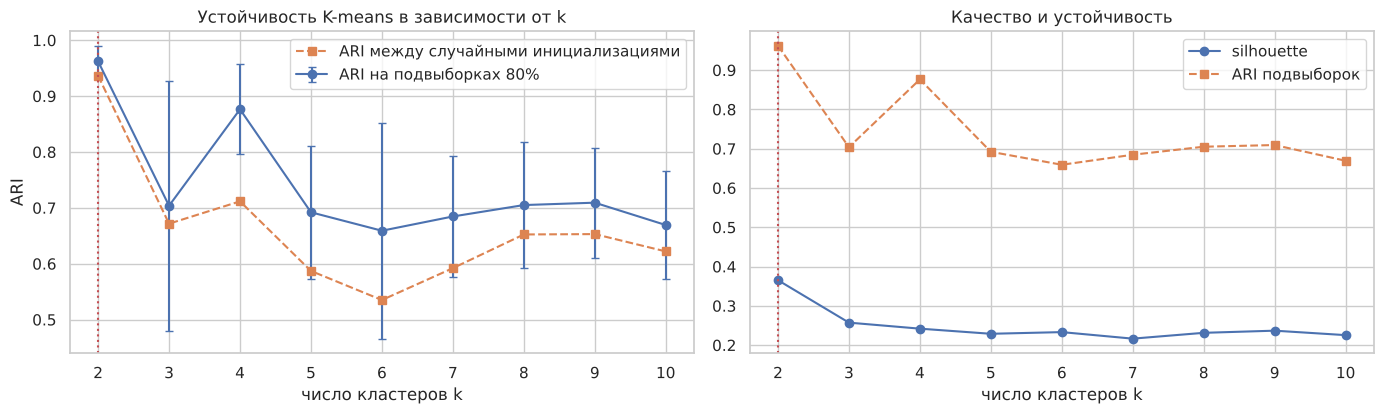

In [19]:
# Влияние числа кластеров k: внутренние метрики (см. таблицу sel) + устойчивость к изменению выборки и инициализации
rng = np.random.default_rng(SEED)
B = 30                                                   # число подвыборок (по 80% объектов)
subs = [rng.choice(len(X), int(0.8 * len(X)), replace=False) for _ in range(B)]

def stability_kmeans(k):
    ref = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    ari_sub = [adjusted_rand_score(ref[s], KMeans(n_clusters=k, n_init=10, random_state=b).fit_predict(X[s]))
               for b, s in enumerate(subs)]
    labs = [KMeans(n_clusters=k, n_init=1, random_state=b).fit(X) for b in range(B)]    # одна инициализация на запуск
    ari_seed = [adjusted_rand_score(ref, l.labels_) for l in labs]
    inert = [l.inertia_ for l in labs]
    return np.mean(ari_sub), np.std(ari_sub), np.mean(ari_seed), np.min(ari_seed), np.mean(inert), np.std(inert)

st = pd.DataFrame([stability_kmeans(k) for k in KS], index=pd.Index(KS, name="k"),
                  columns=["ARI подвыборок (ср.)", "ARI подвыборок (σ)", "ARI между запусками n_init=1 (ср.)",
                           "ARI между запусками (мин.)", "inertia (n_init=1, ср.)", "inertia (n_init=1, σ)"])
display(st)
weak = st[st["ARI подвыборок (ср.)"] < 0.90]["ARI подвыборок (ср.)"].round(3)
print("Значения k с ARI на подвыборках < 0.90 («провалы» устойчивости):", weak.to_dict())
print(f"ARI подвыборок при выбранном k = {K_KM}: {st.loc[K_KM, 'ARI подвыборок (ср.)']:.3f} ± {st.loc[K_KM, 'ARI подвыборок (σ)']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
axes[0].errorbar(KS, st["ARI подвыборок (ср.)"], st["ARI подвыборок (σ)"], fmt="o-", capsize=3, label="ARI на подвыборках 80%")
axes[0].plot(KS, st["ARI между запусками n_init=1 (ср.)"], "s--", label="ARI между случайными инициализациями")
axes[0].axvline(K_KM, color="#C44E52", ls=":"); axes[0].set_xlabel("число кластеров k"); axes[0].set_ylabel("ARI")
axes[0].set_title("Устойчивость K-means в зависимости от k"); axes[0].legend()
axes[1].plot(KS, sel["silhouette K-means"], "o-", label="silhouette"); axes[1].plot(KS, st["ARI подвыборок (ср.)"], "s--", label="ARI подвыборок")
axes[1].axvline(K_KM, color="#C44E52", ls=":"); axes[1].set_xlabel("число кластеров k"); axes[1].set_title("Качество и устойчивость"); axes[1].legend()
plt.tight_layout(); plt.show()


**Пояснение к блоку кода.** Исследуем влияние **числа кластеров *k*** на результат K-means. Помимо метрик качества (раздел 5), оцениваем устойчивость: (а) ARI между разбиением всей выборки и разбиением 80%-подвыборок (30 повторений, на общих объектах); (б) ARI между разбиениями, полученными при 30 различных случайных инициализациях (`n_init=1`) — показывает, насколько результат зависит от старта. ARI = 1 — полное совпадение (с точностью до перестановки меток), ≈ 0 — случайное. В конце выводятся значения *k*, для которых ARI на подвыборках < 0.90.

**Вывод.** С ростом *k* инерция монотонно убывает (748 → 316), поэтому по ней одной выбирать *k* нельзя. Устойчивость немонотонна: **высока при *k* = 2 (0.962 ± 0.028)**, и это единственное значение, где она выше 0.9, а при *k* ≥ 3 ARI ниже 0.9 — **провалы при *k* = 3 (0.704 ± 0.223) и *k* = 5 (0.692 ± 0.119)**, при *k* = 6 лишь 0.659 ± 0.193; *k* = 4 — локальный максимум среди *k* ≥ 3 (0.876 ± 0.081), что согласуется с дендрограммой (второй по величине запас). Очень большой σ при *k* = 3 (0.22) означает, что положение границ в таких разбиениях сильно зависит от состава выборки: непрерывный градиент режется на три части «по-разному» в зависимости от того, какие страны попали в выборку. Таким образом, *k* = 2 — единственное значение, которое одновременно даёт лучшее качество (силуэт, CH, DB) и высокую устойчивость; *k* = 4 — разумная детализация. При одной инициализации (`n_init=1`) результаты разных запусков при *k* = 2 в среднем совпадают с эталонным разбиением хорошо (ARI 0.94), но минимум равен **0.004** — отдельные запуски приходят к совершенно другому разбиению (плохому локальному минимуму); средняя инерция при этом 760.7 ± 66.5 против 748.2 в оптимуме.

In [20]:
# Детализация: K-means при k = K_ALT = 4 (значение, на которое указывает «локоть»); основной разбор выше выполнен при k = K_KM
km4 = KMeans(n_clusters=K_ALT, n_init=10, random_state=SEED).fit(X)
lab4 = relabel(km4.labels_)
print(f"k = {K_ALT}: силуэт {silhouette_score(X, lab4):.3f}, CH {calinski_harabasz_score(X, lab4):.1f}, DB {davies_bouldin_score(X, lab4):.3f}, "
      f"размеры {np.bincount(lab4).tolist()}, ARI подвыборок {st.loc[K_ALT, 'ARI подвыборок (ср.)']:.3f}")
g4 = orig.groupby(lab4); prof4 = g4.median(); prof4.insert(0, "размер", g4.size())
prof4["главный регион"] = df.groupby(lab4)["Region"].agg(lambda s: s.value_counts().index[0])
prof4["его доля, %"] = df.groupby(lab4)["Region"].agg(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
display(prof4)
print("Как кластеры k = 4 вкладываются в кластеры k = 2 (строки — k = 4, столбцы — k = 2):")
display(pd.crosstab(pd.Series(lab4, name="k=4"), pd.Series(lab_km, name="k=2 (K-means)")))
for c in range(K_ALT):
    print(f"Кластер {c} (k=4):", ", ".join(df.loc[lab4 == c, "Country"].head(10)), "…")


k = 4: силуэт 0.242, CH 88.7, DB 1.294, размеры [44, 31, 48, 62], ARI подвыборок 0.876

,размер,"ВВП на душу, $","Продолжительность жизни, лет","Рождаемость, ‰","Городское население, %","CO2 на душу, т","Леса, %","Сельхозземли, %",главный регион,"его доля, %"
0,44,830.0000,63.2500,33.9050,37.0900,0.2495,20.0000,48.0000,SUB-SAHARAN AFRICA,83.3333
1,31,"4,142.0000",71.3000,20.7900,56.0724,1.9973,58.0000,20.0000,LATIN AMER. & CARIB,36.6667
2,48,"4,863.0000",74.1000,18.2150,61.5540,2.6311,13.0000,55.0000,LATIN AMER. & CARIB,21.2766
3,62,"27,577.5000",80.0500,10.6000,80.2345,6.3338,35.0000,31.5000,WESTERN EUROPE,32.7869


Как кластеры k = 4 вкладываются в кластеры k = 2 (строки — k = 4, столбцы — k = 2):


k=2 (K-means),0,1
k=4,,
0,44,0
1,12,19
2,11,37
3,0,62


Кластер 0 (k=4): Eritrea, Kiribati, Rwanda, Somalia, Angola, Comoros, Pakistan, Chad, Timor-Leste, Sierra Leone …
Кластер 1 (k=4): Federated States of Micronesia, Grenada, North Korea, Saint Lucia, Saint Kitts and Nevis, Palau, Ecuador, Marshall Islands, Seychelles, Belize …
Кластер 2 (k=4): Tonga, Saudi Arabia, Turkey, Argentina, Hungary, Romania, Lebanon, Uruguay, Guatemala, Morocco …
Кластер 3 (k=4): Austria, Denmark, Finland, Iceland, Liechtenstein, Norway, Singapore, Sweden, Switzerland, United Arab Emirates …


### Детализация: K-means при *k* = 4 («локоть»)

**Пояснение к блоку кода.** Поскольку метод локтя и вторая по величине зона на дендрограмме указывают на *k* = 4, разбор детализирован для этого значения: метрики, размеры, медианы признаков в исходных единицах, состав по регионам и вложенность в основное разбиение (*k* = 2).

**Вывод.** При *k* = 4 силуэт 0.242 (CH 88.7, DB 1.294), ARI на подвыборках 0.876 — структура слабее и менее устойчива, чем при *k* = 2, поэтому *k* = 4 используется как типология, а не как «естественное» число групп. Кластеры (размер; медианы): **0 — «наименее развитые»** (44; ≈ 830 $, 63.3 года, рождаемость 33.9‰, город 37%; 83% с известным регионом — Африка к югу от Сахары); **1 — «лесные страны среднего дохода»** (31; ≈ 4 100 $, 71.3 года; **лес 58%**, сельхозземли 20%; главный регион — Латинская Америка, 37%, остальное — смесь регионов, много островных государств); **2 — «аграрные страны среднего дохода»** (48; ≈ 4 900 $, 74.1 года; **лес 13%, сельхозземли 55%**; смесь регионов, главный — Латинская Америка, 21%); **3 — «развитые страны»** (62; ≈ 27 600 $, 80.1 года, рождаемость 10.6‰, город 80%, CO₂ 6.3 т на человека; Западная Европа — 33%). Кластеры 1 и 2 по уровню развития почти не различаются, они разделены **землепользованием** (вторая главная компонента), т.е. при *k* = 4 появляется содержательное измерение, которого нет при *k* = 2. Вложенность: кластер 0 (*k* = 4) целиком лежит в менее развитом кластере 0 (*k* = 2), кластер 3 — целиком в более развитом кластере 1; средние кластеры 1 и 2 делятся между ними (12 + 11 стран попадают в менее развитый, 19 + 37 — в более развитый). Следовательно, **граница *k* = 2 проходит через «срединную» полосу** (кластеры 1–2), а крайние сегменты (0 и 3) устойчивы при любом *k*.

In [21]:
# Влияние инициализации и n_init на результат K-means при выбранном k
rows = []
for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        inert, sil = [], []
        for seed in range(50):
            m = KMeans(n_clusters=K_KM, init=init, n_init=n_init, random_state=seed).fit(X)
            inert.append(m.inertia_); sil.append(silhouette_score(X, m.labels_))
        rows.append({"init": init, "n_init": n_init, "inertia, мин.": np.min(inert), "inertia, макс.": np.max(inert),
                     "inertia, σ": np.std(inert), "доля запусков с лучшей inertia, %": np.mean(np.isclose(inert, np.min(inert), rtol=1e-6)) * 100,
                     "silhouette, ср.": np.mean(sil)})
init_tab = pd.DataFrame(rows).set_index(["init", "n_init"])
init_tab


inertia, мин.  inertia, макс.  inertia, σ  доля запусков с лучшей inertia, %  silhouette, ср.
init      n_init                                                                                               
random    1            748.1908        748.3218      0.0260                             2.0000           0.3650
          10           748.1908        748.3103      0.0538                            26.0000           0.3674
k-means++ 1            748.1908      1,119.0459     51.9025                             2.0000           0.3616
          10           748.1908        748.3103      0.0545                            28.0000           0.3675

**Пояснение к блоку кода.** Для *k* = 2 сравниваем способы инициализации (`random` и `k-means++`) при `n_init` = 1 и 10 на 50 разных зёрнах: диапазон инерции, доля запусков, нашедших лучшее значение, и средний силуэт.

**Вывод.** Строгое лучшее значение инерции (748.1908) при `n_init = 1` находят лишь **2%** запусков при обоих способах, а при `n_init = 10` — **26%** (`random`) и **28%** (`k-means++`). Но эти цифры надо читать вместе с разбросом: при `random` все запуски лежат в узком диапазоне 748.19–748.32 (разница 0.02%), т.е. «не лучший» минимум практически не отличим от лучшего (это два очень близких локальных минимума, отличающихся положением нескольких пограничных стран). Опасность другая: при `k-means++` и `n_init = 1` максимум инерции достигает **1119.05** (+50%), σ = 51.9 — отдельные запуски застревают в совершенно плохом разбиении (согласуется с минимальным ARI 0.004 между запусками в разделе выше; вероятная причина — неудачный выбор двух крайних стартовых центров). При `n_init = 10` результат стабилен: инерция 748.19–748.31 при обеих схемах, σ ≈ 0.05, средний силуэт 0.367. Поэтому использование `n_init = 10` (как рекомендовано в задании) оправдано: оно не гарантирует точного глобального минимума, но исключает неудачные запуски. Оценки этого блока относятся к *k* = 2.

In [22]:
# Влияние способа расчёта расстояния между кластерами в иерархической кластеризации: k = K_HC (выбранное) и k = K_ALT (детализация)
rows = []
for kk in sorted({K_HC, K_ALT}):
  ref_w = fcluster(linkage(X, method="ward"), t=kk, criterion="maxclust") - 1
  for method in ["ward", "complete", "average", "single"]:
    Zm = linkage(X, method=method)
    lab = fcluster(Zm, t=kk, criterion="maxclust") - 1
    sizes = sorted(np.bincount(lab).tolist(), reverse=True)
    rows.append({"k": kk, "linkage": method, "кофенетическая корреляция": cophenet(Zm, pdist(X))[0],
                 "размеры кластеров": sizes, "наименьший кластер, % выборки": min(sizes) / len(X) * 100,
                 "Silhouette": silhouette_score(X, lab), "Calinski–Harabasz": calinski_harabasz_score(X, lab),
                 "Davies–Bouldin": davies_bouldin_score(X, lab),
                 "ARI с Ward": adjusted_rand_score(ref_w, lab)})
link_tab = pd.DataFrame(rows).set_index(["k", "linkage"])
link_tab


кофенетическая корреляция размеры кластеров  наименьший кластер, % выборки  Silhouette  Calinski–Harabasz  Davies–Bouldin  ARI с Ward
k linkage                                                                                                                                        
2 ward                         0.6081         [109, 76]                        41.0811      0.3327           121.7760          1.1568      1.0000
  complete                     0.6802         [122, 63]                        34.0541      0.3682           129.6697          1.0802      0.7366
  average                      0.6958         [122, 63]                        34.0541      0.3615           125.1378          1.1012      0.7366
  single                       0.3690          [184, 1]                         0.5405      0.1716             1.8297          0.6945     -0.0033
4 ward                         0.6081  [88, 47, 29, 21]                        11.3514      0.1968            75.5968          1.3395      1.0000
  complete                     0.6802  [81, 47, 41, 16]                         8.6486      0.1927            72.2947          1.6081      0.4462
  average                      0.6958  [121, 48, 15, 1]                         0.5405      0.2362            56.4905          1.0205      0.5407
  single                       0.3690    [182, 1, 1, 1]                         0.5405      0.0101             1.5459          0.7784      0.0064

**Пояснение к блоку кода.** Для иерархической кластеризации сравниваем способы расчёта расстояния между кластерами — Уорд (`ward`), полная связь (`complete`), средняя связь (`average`) и одиночная связь (`single`) — при выбранном *k* = 2 и при *k* = 4: кофенетическая корреляция (насколько дендрограмма сохраняет исходные расстояния), размеры кластеров, доля наименьшего кластера, метрики качества и ARI относительно Уорда (при том же *k*).

**Вывод.** *k* = 2. По формальным метрикам Уорд здесь **не лучший**: силуэт 0.333 против 0.368 (полная связь) и 0.362 (средняя), CH 121.8 против 129.7 и 125.1; полная и средняя связи дают разбиения одинаковых размеров (122 и 63) с одним и тем же ARI относительно Уорда (0.737). Одиночная связь вырождается из-за «эффекта цепочки»: кластер из 184 стран и один из 1 страны (0.5%), силуэт 0.17, низкий DB = 0.69 обманчив — он оценивает вырожденное разбиение. Кофенетическая корреляция умеренная: 0.696 (средняя), 0.680 (полная), 0.608 (Уорд), 0.369 (одиночная). *k* = 4. Метрики формально выше у **средней связи (силуэт 0.236 против 0.197 у Уорда), но разбиение несбалансировано: размеры 121, 48, 15 и 1**, один кластер состоит из единственной страны (0.5% выборки) — высокий силуэт получен за счёт отделения выбросов и не означает лучшей сегментации; полная связь даёт 81, 47, 41, 16 (силуэт 0.193), Уорд — самые ровные размеры (88, 47, 29, 21; наименьший кластер 11%). Выбор Уорда обоснован не «лучшими» метриками при *k* = 2, а согласованностью критерия с K-means (минимизация внутрикластерной дисперсии), сбалансированностью кластеров при большем *k* и интерпретируемостью дендрограммы; при *k* = 2 близкую по качеству альтернативу даёт полная связь.

,K-means,Ward
"ARI на подвыборках 80%, ср.",0.9623,0.5985
"ARI на подвыборках 80%, σ",0.0281,0.1467
"ARI при шуме σ=0.1, ср.",0.9605,0.5146
"ARI при шуме σ=0.1, σ",0.0271,0.1361


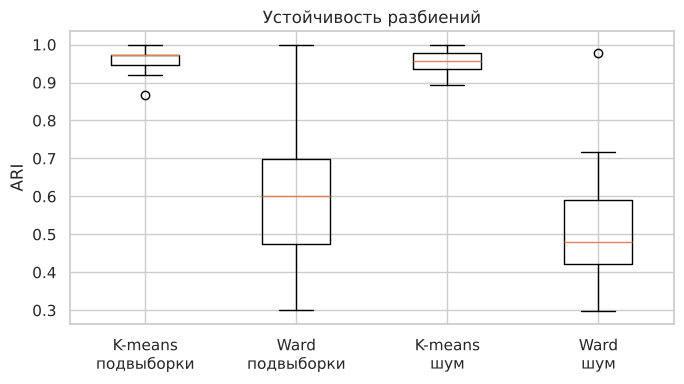

In [23]:
# Устойчивость двух выбранных методов при k = K_KM и k = K_HC: ARI результата на 80%-подвыборке и полного разбиения
ari_km = [adjusted_rand_score(lab_km[s], KMeans(n_clusters=K_KM, n_init=10, random_state=b).fit_predict(X[s])) for b, s in enumerate(subs)]
ari_hc = [adjusted_rand_score(lab_hc[s], AgglomerativeClustering(n_clusters=K_HC, linkage="ward").fit_predict(X[s])) for s in subs]

# и с добавлением шума: гауссов шум σ = 0.1 (в единицах стандартизованных признаков)
ari_km_n, ari_hc_n = [], []
for b in range(B):
    Xn = X + np.random.default_rng(1000 + b).normal(0, 0.1, X.shape)
    ari_km_n.append(adjusted_rand_score(lab_km, KMeans(n_clusters=K_KM, n_init=10, random_state=b).fit_predict(Xn)))
    ari_hc_n.append(adjusted_rand_score(lab_hc, AgglomerativeClustering(n_clusters=K_HC, linkage="ward").fit_predict(Xn)))

stab = pd.DataFrame({"K-means": [np.mean(ari_km), np.std(ari_km), np.mean(ari_km_n), np.std(ari_km_n)],
                     "Ward": [np.mean(ari_hc), np.std(ari_hc), np.mean(ari_hc_n), np.std(ari_hc_n)]},
                    index=["ARI на подвыборках 80%, ср.", "ARI на подвыборках 80%, σ", "ARI при шуме σ=0.1, ср.", "ARI при шуме σ=0.1, σ"])
display(stab)
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([ari_km, ari_hc, ari_km_n, ari_hc_n])
ax.set_xticklabels(["K-means\nподвыборки", "Ward\nподвыборки", "K-means\nшум", "Ward\nшум"])
ax.set_ylabel("ARI"); ax.set_title("Устойчивость разбиений"); plt.tight_layout(); plt.show()


**Пояснение к блоку кода.** Сравниваем устойчивость двух выбранных методов при *k* = 2: (а) ARI разбиения 80%-подвыборки с разбиением всей выборки (на общих объектах), (б) ARI разбиения данных с добавленным гауссовым шумом σ = 0.1 (в единицах стандартизованных признаков) с исходным разбиением. По 30 повторений.

**Вывод.** K-means существенно устойчивее: ARI на подвыборках **0.962 ± 0.028** против **0.599 ± 0.147** у Уорда; при шуме σ = 0.1 — **0.961 ± 0.027** против **0.515 ± 0.136**. Иерархическая процедура **чувствительна даже к малому шуму** (σ = 0.1 — десятая доля стандартного отклонения признака): ARI падает до ≈ 0.5, т.е. почти половина «парных связей» между странами меняется. Причина — необратимость слияний и непрерывность данных: последнее слияние объединяет две большие ветви, граница между которыми определяется тем, какие страны средней полосы оказались раньше присоединены к одной из ветвей, и небольшие сдвиги меняют эту последовательность. K-means пересчитывает центры и перераспределяет объекты на каждой итерации, поэтому граница смещается мало. Оба метода дают ARI значительно выше случайного (≈ 0), т.е. общее деление на «менее» и «более» развитые воспроизводимо, но положение границы у Уорда нестабильно; на практике ему доверять нужно меньше, чем K-means.

## 11. Сравнение методов

In [24]:
def pair_counts(a, b):
    """Пары объектов (i<j): вместе в обоих разбиениях / только в a / только в b / в разных в обоих. Считаем напрямую по таблице сопряжённости."""
    M = contingency_matrix(a, b)
    c2 = lambda x: x * (x - 1) / 2
    both = c2(M).sum()
    only_a = c2(M.sum(axis=1)).sum() - both          # вместе в a (строки), но не вместе в b
    only_b = c2(M.sum(axis=0)).sum() - both          # вместе в b (столбцы), но не вместе в a
    total = c2(len(a))
    return both, only_a, only_b, total - both - only_a - only_b

def pair_metrics(a, b):
    both, only_a, only_b, neither = pair_counts(a, b)
    # проверка по sklearn: pair_confusion_matrix считает упорядоченные пары (×2); C[1,0] — пары «вместе в a, врозь в b», C[0,1] — наоборот
    C_ = pair_confusion_matrix(a, b) / 2
    assert np.allclose([both, only_a, only_b, neither], [C_[1, 1], C_[1, 0], C_[0, 1], C_[0, 0]])
    h, c, v = homogeneity_completeness_v_measure(a, b)
    return {"Rand": rand_score(a, b), "ARI": adjusted_rand_score(a, b),
            "Jaccard (по парам)": both / (both + only_a + only_b),
            "NMI": normalized_mutual_info_score(a, b), "Homogeneity": h, "Completeness": c, "V-measure": v,
            "пар «вместе в обоих»": both, "пар «только в 1-м разбиении»": only_a, "пар «только во 2-м»": only_b}

cmp_methods = pd.Series(pair_metrics(lab_km, lab_hc), name="K-means vs Ward")
known = df["Region"].notna().values                    # регион известен не у всех стран
reg = pd.factorize(df.loc[known, "Region"])[0]
cmp_region = pd.DataFrame({"K-means vs регион": pair_metrics(reg, lab_km[known]),
                           "Ward vs регион": pair_metrics(reg, lab_hc[known])})
print(f"Сравнение с регионом — по {known.sum()} странам с известным регионом ({len(np.unique(reg))} регионов).")
display(pd.concat([cmp_methods, cmp_region], axis=1))

# «потолок» ARI при сравнении с регионом: насколько ARI между регионом и случайным разбиением тех же размеров
rr = np.random.default_rng(SEED)
null_ari = [adjusted_rand_score(reg, rr.permutation(lab_km[known])) for _ in range(500)]
print(f"ARI(регион, случайная перестановка меток K-means): {np.mean(null_ari):.4f} ± {np.std(null_ari):.4f} (макс. из 500: {np.max(null_ari):.4f})")

print("\nТаблица сопряжённости (строки — K-means, столбцы — Ward):")
ct = pd.crosstab(pd.Series(lab_km, name="K-means"), pd.Series(lab_hc, name="Ward")); display(ct)
print("Доля объектов каждого кластера K-means, попавших в «основной» кластер Ward, %:")
print((ct.max(axis=1) / ct.sum(axis=1) * 100).round(1).to_dict())
full = [(int(i), int(j)) for i in ct.index for j in ct.columns if ct.loc[i, j] == ct.loc[i].sum() == ct[j].sum()]
print("Пары кластеров (K-means, Ward), совпавшие полностью (состав одинаков):", full if full else "нет")

from scipy.optimize import linear_sum_assignment
r_, c_ = linear_sum_assignment(-ct.values)                            # оптимальное сопоставление кластеров двух методов (венгерский алгоритм)
match = dict(zip(ct.index[r_], ct.columns[c_]))
print("Сопоставление кластеров (K-means → Ward):", {int(k): int(v) for k, v in match.items()})
print("Доля кластера Ward, лежащая внутри сопоставленного кластера K-means, %:",
      {int(v): round(ct.loc[k, v] / ct[v].sum() * 100, 1) for k, v in match.items()})
mism = np.array([match[a] != b for a, b in zip(lab_km, lab_hc)])
diff = df.loc[mism, ["Country", "Region", "KMeans", "Ward"]].join(df.loc[mism, FEATURES].round(2))
print(f"Число объектов, на которых методы расходятся: {len(diff)} из {len(df)} ({len(diff)/len(df)*100:.1f}%); показаны ВСЕ {len(diff)}:")
display(diff)


Сравнение с регионом — по 180 странам с известным регионом (11 регионов).


,K-means vs Ward,K-means vs регион,Ward vs регион
Rand,0.8322,0.5418,0.5531
ARI,0.6638,0.1325,0.1280
Jaccard (по парам),0.7241,0.1947,0.1910
NMI,0.5617,0.2248,0.2288
Homogeneity,0.5713,0.1471,0.1509
Completeness,0.5523,0.4765,0.4728
V-measure,0.5617,0.2248,0.2288
пар «вместе в обоих»,"7,497.0000","1,785.0000","1,700.0000"
пар «только в 1-м разбиении»,"1,617.0000",480.0000,565.0000
пар «только во 2-м»,"1,239.0000","6,901.0000","6,634.0000"


ARI(регион, случайная перестановка меток K-means): 0.0003 ± 0.0076 (макс. из 500: 0.0251)

Таблица сопряжённости (строки — K-means, столбцы — Ward):


Ward,0,1
K-means,,
0,63,4
1,13,105


Доля объектов каждого кластера K-means, попавших в «основной» кластер Ward, %:
{0: 94.0, 1: 89.0}
Пары кластеров (K-means, Ward), совпавшие полностью (состав одинаков): нет
Сопоставление кластеров (K-means → Ward): {0: 0, 1: 1}
Доля кластера Ward, лежащая внутри сопоставленного кластера K-means, %: {0: np.float64(82.9), 1: np.float64(96.3)}
Число объектов, на которых методы расходятся: 17 из 185 (9.2%); показаны ВСЕ 17:


,Country,Region,KMeans,Ward,GDPpc,LifeExp,Birthrate,Urban,CO2pc,Forest,AgriLand
9,North Korea,ASIA (EX. NEAR EAST),1,0,3.1000,72.1000,13.8900,62.1300,0.0400,41.0000,22.0000
68,Belize,LATIN AMER. & CARIB,1,0,3.6800,74.5000,20.7900,45.8700,0.1600,60.0000,7.0000
69,Guatemala,LATIN AMER. & CARIB,1,0,3.6600,74.1000,24.5600,51.4400,0.0000,33.0000,36.0000
75,Paraguay,LATIN AMER. & CARIB,1,0,3.7300,74.1000,20.5700,61.8800,0.0200,38.0000,55.0000
81,Gabon,SUB-SAHARAN AFRICA,1,0,3.8800,66.2000,31.6100,89.7400,0.3900,90.0000,20.0000
82,Bolivia,LATIN AMER. & CARIB,1,0,3.5500,71.2000,21.7500,69.7700,0.2700,50.0000,35.0000
84,Fiji,OCEANIA,1,0,3.7900,67.3000,21.2800,56.7500,0.3600,56.0000,23.0000
87,Djibouti,SUB-SAHARAN AFRICA,0,1,3.5300,66.6000,21.4700,77.9100,-0.2000,0.0000,73.0000
99,Syria,NEAR EAST,0,1,3.3700,71.8000,23.6900,54.8200,0.2300,3.0000,76.0000
100,Honduras,LATIN AMER. & CARIB,1,0,3.4100,75.1000,21.6000,57.7300,0.0000,40.0000,29.0000


**Пояснение к блоку кода.** Сравниваем два разбиения с помощью внешних метрик, которые измеряют согласованность двух разбиений независимо от нумерации кластеров: индекс Rand (RI), скорректированный ARI, индекс Жаккара по парам объектов, NMI, однородность, полнота и V-мера. Они рассчитаны для двух пар: **K-means против Уорда** и **каждый метод против региона** (регион известен у 180 из 185 стран, 11 регионов). Регион — справочная группировка, а не «истинные классы»; метрики здесь показывают, насколько кластеры воспроизводят географию.

**Как читать пары.** Функция `pair_counts` считает пары стран (*i* < *j*) напрямую по таблице сопряжённости и разделяет их на четыре типа: «вместе в обоих разбиениях», «только в первом» (`only_a`: вместе в первом, врозь во втором), «только во втором» (`only_b`: вместе во втором, врозь в первом) и «врозь в обоих». Содержание `only_a` и `only_b` зависит от **порядка аргументов** `pair_metrics(a, b)`: в сравнении «регион vs кластеры» первый аргумент — регион, поэтому `only_a` = пары стран из одного региона, но разных кластеров, а `only_b` = пары из одного кластера, но разных регионов; в сравнении «K-means vs Ward» первый — K-means. Верность подписей проверяется внутри функции: счётчики сверяются с `pair_confusion_matrix` из scikit-learn (там `C[1,0]` — пары «вместе в a, врозь в b», `C[0,1]` — наоборот; учтено, что sklearn считает упорядоченные пары, т.е. вдвое больше). Для Жаккара (`both / (both + only_a + only_b)`) порядок не важен, но для содержательного разбора он нужен.

Далее — таблица сопряжённости, оптимальное сопоставление кластеров методов (венгерский алгоритм) и **полный** список объектов, на которых методы расходятся (число строк в таблице равно общему числу расхождений — без усечения вывода).

**Вывод. Согласованность методов.** Rand = 0.832, ARI = 0.664, Жаккар = 0.724, NMI = V-мера = 0.562 (однородность 0.571, полнота 0.552). Согласованность умеренно-хорошая — заметно ниже, чем между методами на «чётких» данных. Таблица сопряжённости: из 67 стран кластера 0 K-means 63 (94%) попали в кластер 0 Уорда, из 118 стран кластера 1 — 105 (89%) в кластер 1; наоборот, кластер 0 Уорда на 83% (63 из 76) лежит в кластере 0 K-means, а кластер 1 — на 96% (105 из 109) в кластере 1. **Полностью совпавших кластеров нет**. Устойчивое «ядро» — 63 страны, отнесённые к менее развитым обоими методами, и 105 — к более развитым (168 из 185, 90.8%). Методы расходятся на **17 из 185 стран (9.2%)** — в таблице показаны **все 17** (в отличие от усечённого вывода первых строк): 13 стран K-means относит к более развитым, а Уорд — к менее развитым (Северная Корея, Белиз, Гватемала, Парагвай, Габон, Боливия, Фиджи, Гондурас, Гайана, Кабо-Верде, Индонезия, Бутан, Ботсвана), а 4 страны — наоборот (Джибути, Сирия, Египет, Узбекистан). Все расходящиеся объекты — пограничные: log₁₀ ВВП на душу у них 3.24–3.89 (≈ 1.7–7.8 тыс. $), т.е. из средней полосы градиента, где различие между методами — следствие места, где проведена граница.

**Вывод. Сравнение с регионом.** ARI = 0.133 (K-means) и 0.128 (Уорд), NMI = 0.225 и 0.229, Жаккар = 0.195 и 0.191, Rand = 0.542 и 0.553. **Жаккар 0.19 нельзя читать как «связи нет»**: он показывает долю пар, объединённых одновременно и кластером, и регионом, среди всех пар, объединённых хотя бы одним из разбиений (для K-means: 1 785 пар «вместе в обоих» из 1 785 + 480 + 6 901 = 9 166). Он невелик, потому что кластеров два и они огромные (один лишь кластер 1 из 116 стран с известным регионом даёт 6 670 пар), а регионов одиннадцать и каждый небольшой: подавляющее большинство «кластерных» пар (6 901) — это страны из разных регионов. О наличии связи говорят скорректированные на случайность метрики: **ARI ≈ 0.13 — на 17 стандартных отклонений выше нулевого значения** (при случайной перестановке меток ARI = 0.0003 ± 0.0076, максимум из 500 перестановок — 0.025) и NMI ≈ 0.22 — связь есть, но слабая-умеренная. Несимметрия однородности и полноты (0.15 против 0.48) объясняется так же: регионы редко «разрываются» между кластерами (всего 480 пар «только в регионе»), но кластеры объединяют страны многих регионов. Итог: кластеры отражают уровень развития, а не географию; регион даёт лишь частичное объяснение (бедные страны концентрируются в Африке к югу от Сахары, богатые — в Западной Европе, а середина градиента пересекает почти все регионы).

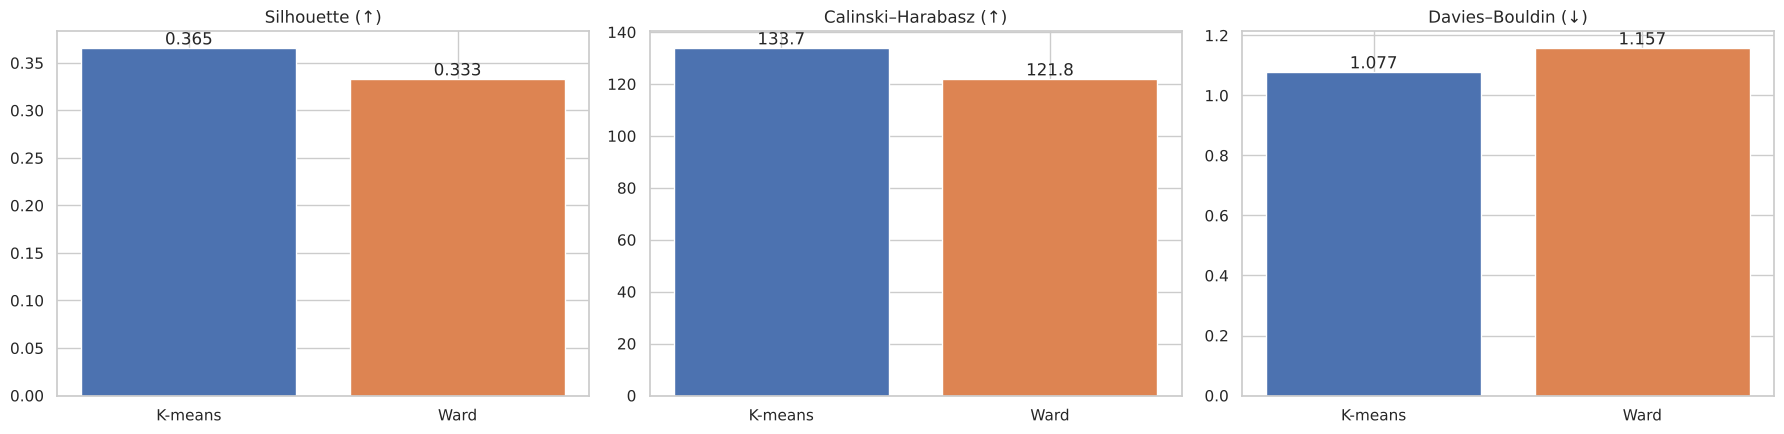

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
cols = ["Silhouette (↑)", "Calinski–Harabasz (↑)", "Davies–Bouldin (↓)"]
for ax, m in zip(axes, cols):
    vals = qual.loc[m]; ax.bar(vals.index, vals.values, color=["#4C72B0", "#DD8452"])
    for i, v in enumerate(vals.values): ax.text(i, v, f"{v:.3f}" if v < 10 else f"{v:.1f}", ha="center", va="bottom")
    ax.set_title(m)
plt.tight_layout(); plt.show()


**Пояснение к блоку кода.** Столбчатые диаграммы сравнивают методы по основным внутренним метрикам: силуэт (↑), индекс CH (↑), индекс DB (↓).

**Вывод.** По всем трём метрикам K-means лучше (силуэт 0.365 против 0.333, CH 134 против 122, DB 1.077 против 1.157). Для этих данных (непрерывный градиент без разрывов) K-means предпочтительнее: лучше по метрикам, **существенно устойчивее** (ARI 0.96 против 0.60 на подвыборках), проще вычислительно. Метод Уорда ценен как независимая проверка и за дендрограмму: именно по ней подтверждено *k* = 2 и выявлен второй по обоснованности вариант *k* = 4. Согласованность методов (ARI 0.66) показывает, что деление на «менее» и «более» развитые реально, а положение границы в середине градиента зависит от алгоритма.

## Заключение

1. **Данные.** Датасет Countries Data Set: 196 стран, 35 числовых показателей, пропуски закодированы символом `?` (приведены к `NaN`). Для кластеризации выбраны семь относительных признаков (`GDPpc`, `LifeExp`, `Birthrate`, `Urban`, `CO2pc`, `Forest`, `AgriLand`; ВВП и CO₂ на душу — в log₁₀) для 185 стран с полными данными (11 исключены). Распределения не строго нормальны (Шапиро–Уилк отвергает нормальность), но после логарифмирования близки к симметричным (|γ| ≤ 0.61). Признаки блока развития сильно коррелируют (|r| = 0.74–0.87), PC1 объясняет 58.0% дисперсии — кластеры будут отражать прежде всего уровень развития; землепользование (`Forest`, `AgriLand`) почти независимо от него.
2. **Условия применимости.** Классов нет; выбросов по правилу трёх сигм нет (max |z| = 2.94), по IQR отмечена одна страна (ДР Конго) — оставлена; статистика Хопкинса 0.705 (при 0.488 для равномерных данных) — структура есть, но выражена умеренно.
3. **Подготовка.** Применён `StandardScaler` (методы основаны на евклидовом расстоянии, признаки измерены в разных единицах). Матрица рассеивания показала не изолированные группы, а непрерывный градиент вдоль оси развития, поэтому выбраны K-means и иерархическая кластеризация Уорда (общий критерий — внутрикластерная дисперсия, разные алгоритмы); DBSCAN не подходит из-за отсутствия плотностных разрывов, GMM — возможное продолжение.
4. **Число кластеров.** Силуэт, индекс Калинского–Харабаза и индекс Дэвиса–Болдина дают *k* = 2 для обоих методов; дендрограмма Уорда подтверждает *k* = 2 (запас по высоте 17.3 — в 6 раз больше, чем у *k* = 4 с запасом 2.77); метод локтя неоднозначен (автоматически *k* = 4). Принято **k = 2**; *k* = 4 разобран как детализация.
5. **Качество.** K-means: силуэт 0.365, CH 133.7, DB 1.077, Dunn 0.122, WCSS 748.2; Уорд: 0.333, 121.8, 1.157, 0.110, 777.6. Структура **слабая** (силуэт ≈ 0.33–0.37 по шкале Кауфмана и Руссо): центры разнесены (3.58 и 3.40) лишь в 1.7–1.9 раза дальше среднего «радиуса» кластера. Индекс Данна определяется парой точек и не используется как основной критерий. Более размыт кластер менее развитых стран (силуэт 0.34 у K-means и 0.285 у Уорда).
6. **Влияние параметров.** Число кластеров *k*: качество и устойчивость максимальны при *k* = 2 (ARI на подвыборках 0.962); провалы при *k* = 3 (0.704) и *k* = 5 (0.692), при *k* = 6 — 0.659; *k* = 4 — локальный максимум (0.876). Инициализация: при `n_init = 1` строгий минимум находят лишь 2% запусков, при `n_init = 10` — 26–28%, причём разброс инерции при `n_init = 10` ничтожен (σ ≈ 0.05), а одиночный запуск `k-means++` может дать инерцию 1119 (+50%). Способ связи: при *k* = 2 полная и средняя связи формально лучше Уорда (силуэт 0.368 и 0.362 против 0.333), при *k* = 4 средняя связь даёт кластер из одной страны (0.5% выборки) при формально более высоком силуэте, одиночная вырождается (эффект цепочки).
7. **Интерпретация.** При *k* = 2: «менее развитые» (67 стран; ≈ 1 400 $ на душу, 64.7 года, рождаемость 31.9‰; 62.5% — Африка к югу от Сахары) и «более развитые» (118 стран; ≈ 12 300 $, 76.6 года, 13.2‰; Латинская Америка, Европа, Ближний Восток). При *k* = 4 добавляются два среднедоходных типа, различающихся землепользованием: «лесные» (лес 58%) и «аграрные» (сельхозземли 55%); крайние сегменты (наименее развитые — 44 страны, развитые — 62 страны) устойчивы и целиком вложены в кластеры *k* = 2.
8. **Сравнение и устойчивость.** Методы согласованы умеренно-хорошо (ARI 0.66, NMI 0.56, Жаккар 0.72): полностью совпавших кластеров нет, расходятся 17 из 185 стран (9.2%), все — из средней полосы ВВП (≈ 1.7–7.8 тыс. $). K-means лучше по метрикам и намного устойчивее (ARI на подвыборках 0.96 против 0.60; при шуме σ = 0.1 — 0.96 против 0.52: иерархическая процедура чувствительна даже к малому шуму), поэтому для итоговой типологии рекомендуется K-means с *k* = 2 (и *k* = 4 для детализации); Уорд служит независимой проверкой. Связь кластеров с регионами слабая-умеренная (ARI ≈ 0.13, NMI ≈ 0.22; Жаккар 0.19 отражает малую долю пар, объединённых одновременно кластером и регионом, а не отсутствие связи).

**Ограничения.** (а) Структура данных — непрерывный градиент: кластеры задают разбиение по уровню развития, но не «естественные группы»; силуэт слабый, а при *k* ≥ 3 устойчивость < 0.9. (б) Признаки развития избыточны (PC1 = 58%): результат во многом определяется одним фактором. (в) Исключены 11 стран с неполными данными (в основном микрогосударства). (г) Регион — справочная группировка, а не истинные классы, поэтому внешние метрики показывают согласованность разбиений, а не точность кластеризации.

## Список источников

1. Dataset: *Countries Data Set* [Электронный ресурс]: файл `Countries Data Set.csv` (196 стран, 37 столбцов), предоставленный в рамках задания. Первоисточник показателей в файле не указан.
2. Pedregosa F. et al. *Scikit-learn: Machine Learning in Python* // Journal of Machine Learning Research. — 2011. — Vol. 12. — P. 2825–2830. Документация: https://scikit-learn.org/stable/modules/clustering.html (разделы «K-means», «Hierarchical clustering», «Clustering performance evaluation»).
3. Rousseeuw P. J. *Silhouettes: a graphical aid to the interpretation and validation of cluster analysis* // Journal of Computational and Applied Mathematics. — 1987. — Vol. 20. — P. 53–65.
4. Kaufman L., Rousseeuw P. J. *Finding Groups in Data: An Introduction to Cluster Analysis*. — New York: Wiley, 1990. (шкала интерпретации среднего силуэта).
5. Caliński T., Harabasz J. *A dendrite method for cluster analysis* // Communications in Statistics. — 1974. — Vol. 3, № 1. — P. 1–27.
6. Hopkins B., Skellam J. G. *A new method for determining the type of distribution of plant individuals* // Annals of Botany. — 1954. — Vol. 18. — P. 213–227.
7. Hubert L., Arabie P. *Comparing partitions* // Journal of Classification. — 1985. — Vol. 2. — P. 193–218.
8. Ward J. H. *Hierarchical grouping to optimize an objective function* // Journal of the American Statistical Association. — 1963. — Vol. 58. — P. 236–244.